In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"

In [ ]:
# ============================================================================
# CELL 1 — ENVIRONMENT (PyTorch). RUN FIRST, IN A FRESH KERNEL.
#
# PORTING NOTE: the old CELL 1 hunted for CUDA `libdevice` because TensorFlow's
# XLA JIT needs it at runtime. PyTorch ships its own precompiled CUDA kernels
# in the wheel, so that entire problem disappears -- there is nothing to find
# and nothing to point XLA at.
#
# What IS worth setting before `import torch` is the caching-allocator config.
# `expandable_segments` lets the allocator grow a segment instead of reserving
# a new one, which markedly reduces fragmentation OOMs when you train several
# ablation variants back-to-back in one kernel (exactly what CELL 18 does).
# Like XLA_FLAGS, it is read ONCE at first torch import -- edit it after that
# and you must restart the kernel.
# ============================================================================
import os

# ---------------------------------------------------------------------------
# DEBUG_CUDA: turn this on the moment you hit any CUDA-level error
# ("misaligned address", "illegal memory access", "device-side assert").
# CUDA kernels launch asynchronously, so by default the Python traceback points
# at whatever call happened to synchronise NEXT -- almost never the real culprit.
# CUDA_LAUNCH_BLOCKING=1 makes every launch synchronous, so the traceback lands
# on the actual failing operation. It costs maybe 10-30% throughput, so turn it
# back off once you have located the problem.
# Like the allocator config, this is read at first torch import: set it here,
# then Kernel > Restart and run from the top.
# ---------------------------------------------------------------------------
DEBUG_CUDA = False

if DEBUG_CUDA:
    os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
    os.environ["TORCH_SHOW_CPP_STACKTRACES"] = "1"
else:
    os.environ.pop("CUDA_LAUNCH_BLOCKING", None)

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # needed if you ever
                                                              # enable deterministic algos
os.environ.setdefault("OMP_NUM_THREADS", "8")

print("Env configured for PyTorch:")
for k in ("PYTORCH_CUDA_ALLOC_CONF", "CUBLAS_WORKSPACE_CONFIG", "OMP_NUM_THREADS"):
    print(f"  {k} = {os.environ[k]}")
print(f"  DEBUG_CUDA = {DEBUG_CUDA}"
      f"{'  <- synchronous launches, tracebacks are trustworthy' if DEBUG_CUDA else ''}")
print("\nNo libdevice / XLA_FLAGS needed -- PyTorch does not JIT-compile via NVVM.")


Env configured for PyTorch:
  PYTORCH_CUDA_ALLOC_CONF = expandable_segments:True
  CUBLAS_WORKSPACE_CONFIG = :4096:8
  OMP_NUM_THREADS = 8
  DEBUG_CUDA = False

No libdevice / XLA_FLAGS needed -- PyTorch does not JIT-compile via NVVM.


In [ ]:
# ============================================================================
# CELL 2 — PART 1: CONFIG & DATASET DISCOVERY
# Unchanged from the TF version: this cell is pure numpy / OpenCV / sklearn and
# has no framework dependency.
#
# PORTING NOTE: the old comment here warned that importing torch stole ~11 GB
# of GPU:0 from TensorFlow. That no longer applies -- torch IS the framework
# now, and it is imported deliberately in CELL 8. Part 1 still does not import
# it, so you can run Part 1 alone without ever creating a CUDA context.
# ============================================================================
import os, re, gc, json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)
sns.set_style("whitegrid")
cv2.setNumThreads(4)

# --- ONE place for every path used by all four parts -----------------------
DATA_ROOT      = "/home/dhrubo/Videos/plos/Dataset"
PROJECT_ROOT   = "/home/dhrubo/Videos/plos/TDN_pipeline"
DATA_DIR       = f"{PROJECT_ROOT}/processed_data"
CHECKPOINT_DIR = f"{PROJECT_ROOT}/checkpoints"
FIGURE_DIR     = f"{PROJECT_ROOT}/paper_figures"
for _d in (DATA_DIR, CHECKPOINT_DIR, FIGURE_DIR):
    os.makedirs(_d, exist_ok=True)

RESOLUTIONS_TO_BUILD = [256, 512]
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")


def _has_token(text, token):
    return re.search(r"(?<![a-z])" + token + r"(?![a-z])", text) is not None


def discover_dataset(root):
    candidates = {"ct_tumor": [], "ct_healthy": [], "mri_tumor": [], "mri_healthy": []}
    root = os.path.abspath(root)
    for dirpath, _, filenames in os.walk(root):
        if not any(f.lower().endswith(IMG_EXT) for f in filenames):
            continue
        rel = os.path.relpath(dirpath, root).lower()
        is_ct, is_mri = _has_token(rel, "ct"), _has_token(rel, "mri")
        is_tumor = _has_token(rel, "tumou?r")
        is_healthy = _has_token(rel, "healthy") or _has_token(rel, "normal") or "no_tumor" in rel
        if is_ct and is_tumor and not is_healthy:      candidates["ct_tumor"].append(dirpath)
        elif is_ct and is_healthy:                      candidates["ct_healthy"].append(dirpath)
        elif is_mri and is_tumor and not is_healthy:    candidates["mri_tumor"].append(dirpath)
        elif is_mri and is_healthy:                     candidates["mri_healthy"].append(dirpath)
    return candidates


assert os.path.isdir(DATA_ROOT), f"DATA_ROOT does not exist: {DATA_ROOT}"
found = discover_dataset(DATA_ROOT)

CT_TUMOR_DIR    = found["ct_tumor"][0]    if found["ct_tumor"]    else None
CT_HEALTHY_DIR  = found["ct_healthy"][0]  if found["ct_healthy"]  else None
MRI_TUMOR_DIR   = found["mri_tumor"][0]   if found["mri_tumor"]   else None
MRI_HEALTHY_DIR = found["mri_healthy"][0] if found["mri_healthy"] else None

DIRS = [CT_TUMOR_DIR, CT_HEALTHY_DIR, MRI_TUMOR_DIR, MRI_HEALTHY_DIR]
USE_REAL_DATA = all(DIRS) and all(os.path.isdir(p) for p in DIRS)

if USE_REAL_DATA:
    print("Auto-discovered dataset paths:")
    for k, v in found.items():
        n = len([f for f in os.listdir(v[0]) if f.lower().endswith(IMG_EXT)])
        print(f"  {k:12s} -> {v[0]}  ({n} images)")
else:
    print("Could not locate all four folders:", {k: bool(v) for k, v in found.items()})

print(f"\nReal dataset usable: {USE_REAL_DATA}")
print("Output directory   :", DATA_DIR)


Auto-discovered dataset paths:
  ct_tumor     -> /home/dhrubo/Videos/plos/Dataset/Brain Tumor CT scan Images/Tumor  (2318 images)
  ct_healthy   -> /home/dhrubo/Videos/plos/Dataset/Brain Tumor CT scan Images/Healthy  (2300 images)
  mri_tumor    -> /home/dhrubo/Videos/plos/Dataset/Brain Tumor MRI images/Tumor  (3000 images)
  mri_healthy  -> /home/dhrubo/Videos/plos/Dataset/Brain Tumor MRI images/Healthy  (2000 images)

Real dataset usable: True
Output directory   : /home/dhrubo/Videos/plos/TDN_pipeline/processed_data


In [ ]:
# ============================================================================
# CELL 3 — PREPROCESSING  (framework-independent, unchanged)
# Storage stays uint8 (4x less RAM). The /255 normalisation happens exactly
# once, on the GPU, inside the training/eval code in Part 3.
# ============================================================================
def preprocess_image(img_gray, target_size):
    """Resize + CLAHE + NLM denoise. Returns uint8 HxWx1 in [0,255]."""
    img_gray = cv2.resize(img_gray, (target_size, target_size))
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img_gray = clahe.apply(img_gray)
    img_gray = cv2.fastNlMeansDenoising(img_gray, h=7)
    return img_gray[..., np.newaxis]


def load_images_from_folder(folder, target_size, limit=None):
    images, names, raw_first = [], [], None
    filenames = sorted(f for f in os.listdir(folder) if f.lower().endswith(IMG_EXT))
    if limit is not None:
        filenames = filenames[:limit]
    for filename in filenames:
        img = cv2.imread(os.path.join(folder, filename), cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        if raw_first is None:
            raw_first = cv2.resize(img, (target_size, target_size))
        images.append(preprocess_image(img, target_size))
        names.append(filename)
    return np.array(images, dtype="uint8"), names, raw_first


def pair_modalities(ct_imgs, mri_imgs, label, seed=42):
    """Truncate to min(len) after a shuffle, so every source image is used at
    most once -- no duplicate landing in both train and test.

    NOTE FOR THE PAPER: this removes image-level leakage only. The four folders
    are independent patient sets, so CT and MRI in a pair are NOT the same
    patient. State this explicitly in Methods -- it constrains what the
    alignment module (N3) can be claimed to do.
    """
    rng = np.random.default_rng(seed)
    n = min(len(ct_imgs), len(mri_imgs))
    ct_idx  = rng.permutation(len(ct_imgs))[:n]
    mri_idx = rng.permutation(len(mri_imgs))[:n]
    return ct_imgs[ct_idx], mri_imgs[mri_idx], np.full((n, 1), label, dtype="float32")


print("Preprocessing functions ready (uint8 storage, non-duplicating pairing).")


Preprocessing functions ready (uint8 storage, non-duplicating pairing).


     Category  Count
   CT — Tumor   2318
 CT — Healthy   2300
  MRI — Tumor   3000
MRI — Healthy   2000


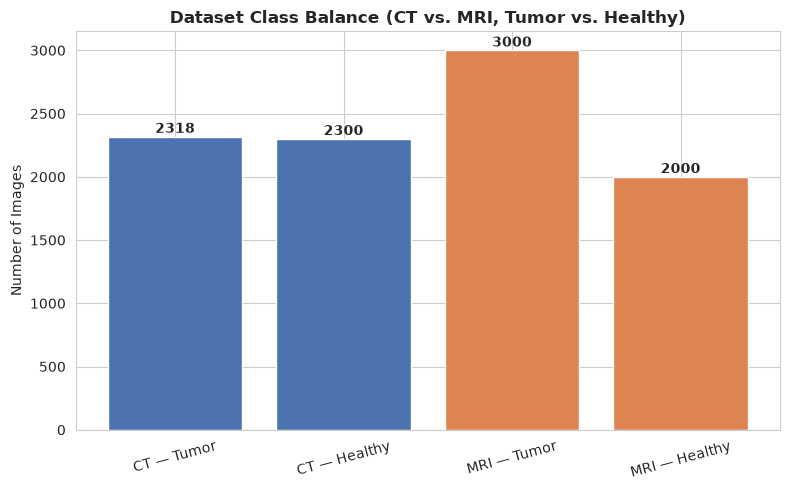

In [ ]:
# ============================================================================
# CELL 4 — CLASS BALANCE FIGURE  (unchanged)
# ============================================================================
counts = {
    "CT — Tumor":    len([f for f in os.listdir(CT_TUMOR_DIR)    if f.lower().endswith(IMG_EXT)]),
    "CT — Healthy":  len([f for f in os.listdir(CT_HEALTHY_DIR)  if f.lower().endswith(IMG_EXT)]),
    "MRI — Tumor":   len([f for f in os.listdir(MRI_TUMOR_DIR)   if f.lower().endswith(IMG_EXT)]),
    "MRI — Healthy": len([f for f in os.listdir(MRI_HEALTHY_DIR) if f.lower().endswith(IMG_EXT)]),
}
counts_df = pd.DataFrame(list(counts.items()), columns=["Category", "Count"])
print(counts_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(counts_df["Category"], counts_df["Count"],
              color=["#4C72B0", "#4C72B0", "#DD8452", "#DD8452"])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + max(counts.values()) * 0.01,
            str(int(b.get_height())), ha="center", fontweight="bold")
ax.set_ylabel("Number of Images")
ax.set_title("Dataset Class Balance (CT vs. MRI, Tumor vs. Healthy)", fontweight="bold")
plt.xticks(rotation=15); plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/fig1a_class_balance.png", dpi=200); plt.show()
counts_df.to_csv(f"{DATA_DIR}/class_balance.csv", index=False)


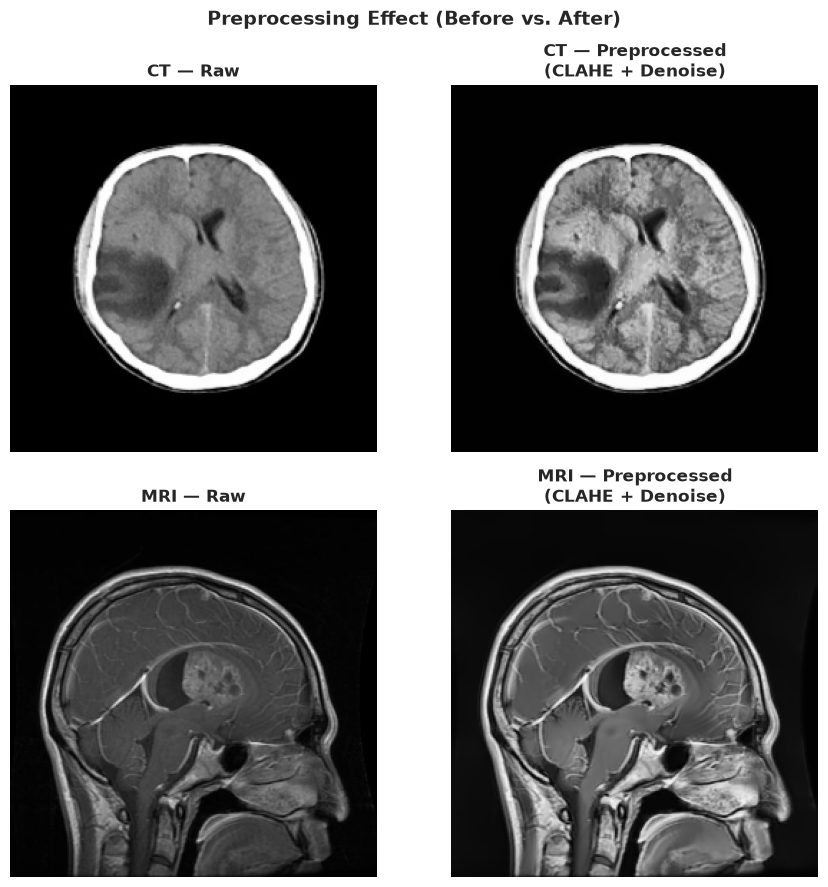

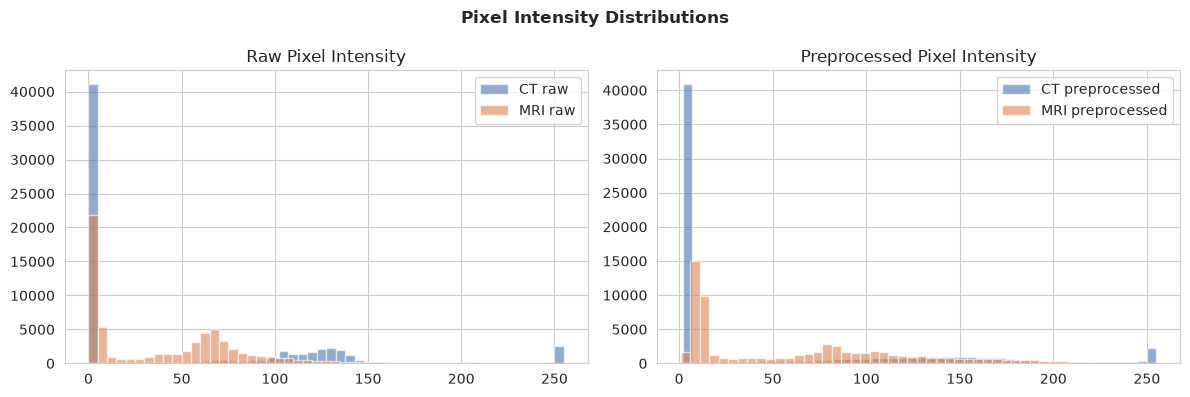

In [ ]:
# ============================================================================
# CELL 5 — PREPROCESSING DEMO FIGURE  (unchanged)
# ============================================================================
demo_res = RESOLUTIONS_TO_BUILD[0]
_, _, raw_ct  = load_images_from_folder(CT_TUMOR_DIR,  demo_res, limit=1)
_, _, raw_mri = load_images_from_folder(MRI_TUMOR_DIR, demo_res, limit=1)

proc_ct  = preprocess_image(raw_ct,  demo_res).squeeze()
proc_mri = preprocess_image(raw_mri, demo_res).squeeze()

fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for ax, img, t in zip(axes.ravel(), [raw_ct, proc_ct, raw_mri, proc_mri],
                      ["CT — Raw", "CT — Preprocessed\n(CLAHE + Denoise)",
                       "MRI — Raw", "MRI — Preprocessed\n(CLAHE + Denoise)"]):
    ax.imshow(img, cmap="gray"); ax.set_title(t, fontweight="bold"); ax.axis("off")
plt.suptitle("Preprocessing Effect (Before vs. After)", fontweight="bold", fontsize=14)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig1b_preprocessing.png", dpi=200); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw_ct.ravel(),  bins=50, alpha=.6, label="CT raw",  color="#4C72B0")
axes[0].hist(raw_mri.ravel(), bins=50, alpha=.6, label="MRI raw", color="#DD8452")
axes[0].set_title("Raw Pixel Intensity"); axes[0].legend()
axes[1].hist(proc_ct.ravel(),  bins=50, alpha=.6, label="CT preprocessed",  color="#4C72B0")
axes[1].hist(proc_mri.ravel(), bins=50, alpha=.6, label="MRI preprocessed", color="#DD8452")
axes[1].set_title("Preprocessed Pixel Intensity"); axes[1].legend()
plt.suptitle("Pixel Intensity Distributions", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig1c_histograms.png", dpi=200); plt.show()


In [ ]:
# ============================================================================
# CELL 6 — BUILD DATASETS  (unchanged)
# The train/val/test split is computed ONCE and written to disk, so Part 3 and
# Part 4 provably evaluate on the same test set.
#
# STORAGE LAYOUT NOTE: the .npy files stay NHWC (N, H, W, 1), exactly as in the
# TF version. PyTorch wants NCHW, but the permutation is done at the tensor
# boundary in Part 3 -- so these arrays, and any you already generated with the
# TF notebook, remain byte-for-byte reusable. Do not re-run Part 1 if you have
# already built them.
# ============================================================================
def build_dataset(target_size):
    ct_tumor,    _, _ = load_images_from_folder(CT_TUMOR_DIR,    target_size)
    ct_healthy,  _, _ = load_images_from_folder(CT_HEALTHY_DIR,  target_size)
    mri_tumor,   _, _ = load_images_from_folder(MRI_TUMOR_DIR,   target_size)
    mri_healthy, _, _ = load_images_from_folder(MRI_HEALTHY_DIR, target_size)

    a_t, b_t, y_t = pair_modalities(ct_tumor,   mri_tumor,   label=1)
    a_h, b_h, y_h = pair_modalities(ct_healthy, mri_healthy, label=0)

    A = np.concatenate([a_t, a_h]); B = np.concatenate([b_t, b_h]); Y = np.concatenate([y_t, y_h])
    # uint8-safe mean. NOTE: this "reference" is just the average of the two
    # inputs -- see CELL 16, where reference-free fusion metrics are the
    # headline numbers and SSIM-vs-mean is demoted to a sanity check.
    REF = ((A.astype("uint16") + B.astype("uint16")) // 2).astype("uint8")

    del ct_tumor, ct_healthy, mri_tumor, mri_healthy, a_t, b_t, a_h, b_h
    gc.collect()
    print(f"[{target_size}] A={A.shape} B={B.shape} Y={Y.shape} "
          f"(tumor={int(Y.sum())}, healthy={int((1-Y).sum())}) dtype={A.dtype}")
    return A, B, Y, REF


datasets = {}
for res in RESOLUTIONS_TO_BUILD:
    print(f"\n--- Building {res}x{res} ---")
    A, B, Y, REF = build_dataset(res)
    np.save(f"{DATA_DIR}/A_{res}.npy", A)
    np.save(f"{DATA_DIR}/B_{res}.npy", B)
    np.save(f"{DATA_DIR}/Y_{res}.npy", Y)
    np.save(f"{DATA_DIR}/REF_{res}.npy", REF)
    print(f"Saved to {DATA_DIR}")

    if res == RESOLUTIONS_TO_BUILD[0]:
        datasets[res] = (A, B, Y, REF)          # keep smallest for the demo figure
        idx = np.arange(len(Y))
        tr, te = train_test_split(idx, test_size=0.2,  stratify=Y,     random_state=42)
        tr, va = train_test_split(tr,  test_size=0.15, stratify=Y[tr], random_state=42)
        np.savez(f"{DATA_DIR}/split_indices.npz", train=tr, val=va, test=te)
        print(f"Canonical split saved: train={len(tr)} val={len(va)} test={len(te)}")
    else:
        datasets[res] = (None, None, Y, None)
        del A, B, REF
    gc.collect()

with open(f"{DATA_DIR}/config.txt", "w") as f:
    f.write(f"RESOLUTIONS={RESOLUTIONS_TO_BUILD}\nUSE_REAL_DATA={USE_REAL_DATA}\n")



--- Building 256x256 ---
[256] A=(4318, 256, 256, 1) B=(4318, 256, 256, 1) Y=(4318, 1) (tumor=2318, healthy=2000) dtype=uint8
Saved to /home/dhrubo/Videos/plos/TDN_pipeline/processed_data
Canonical split saved: train=2935 val=519 test=864

--- Building 512x512 ---
[512] A=(4318, 512, 512, 1) B=(4318, 512, 512, 1) Y=(4318, 1) (tumor=2318, healthy=2000) dtype=uint8
Saved to /home/dhrubo/Videos/plos/TDN_pipeline/processed_data


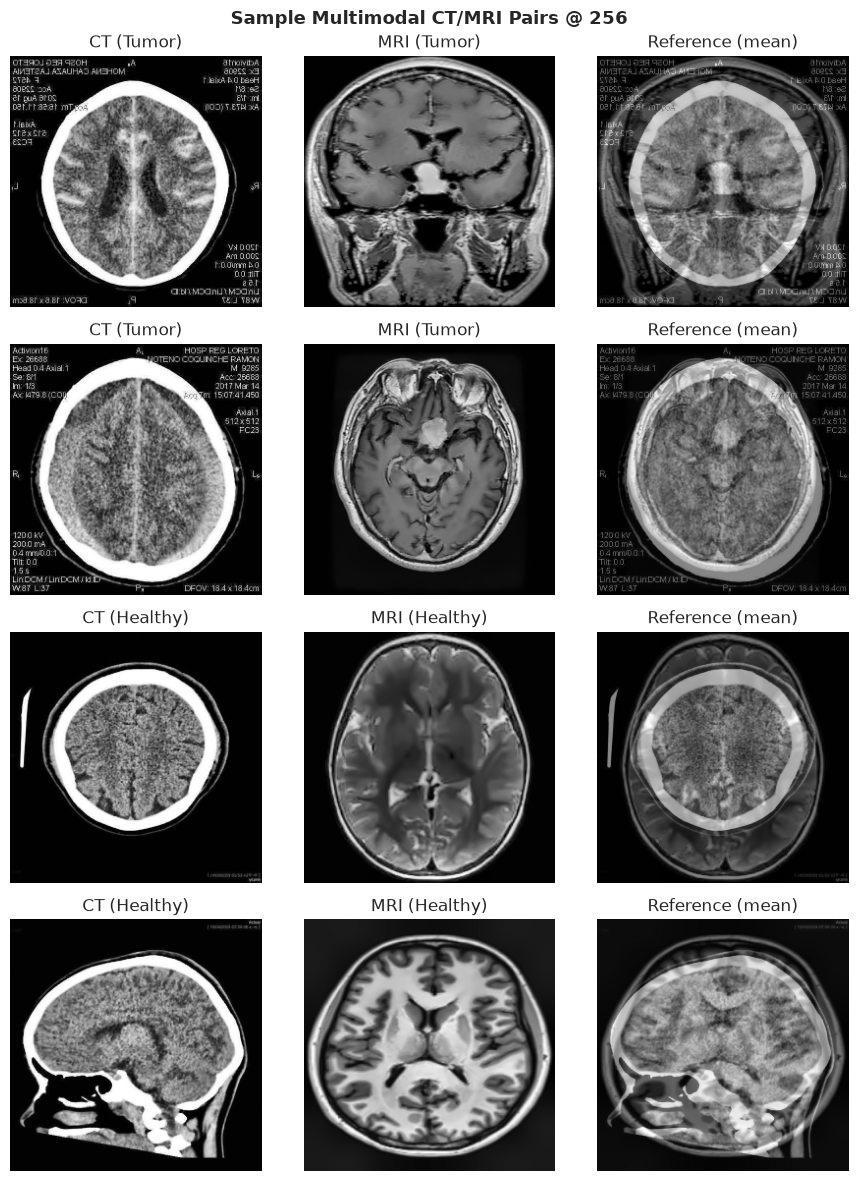

Table 1 — Dataset Split Summary
            Train  Val  Test  Train Tumor%  Test Tumor%
Resolution                                             
256x256      2935  519   864          53.7         53.7
512x512      2935  519   864          53.7         53.7

Part 1 complete.


In [ ]:
# ============================================================================
# CELL 7 — SAMPLE PAIRS + SPLIT SUMMARY  (unchanged)
# ============================================================================
show_res = RESOLUTIONS_TO_BUILD[0]
A, B, Y, REF = datasets[show_res]
_sp = np.load(f"{DATA_DIR}/split_indices.npz")
train_idx, val_idx, test_idx = _sp["train"], _sp["val"], _sp["test"]

rng = np.random.default_rng(1)
sample_idx = np.concatenate([
    rng.choice(np.where(Y.ravel() == 1)[0], size=2, replace=False),
    rng.choice(np.where(Y.ravel() == 0)[0], size=2, replace=False),
])

fig, axes = plt.subplots(len(sample_idx), 3, figsize=(9, 3 * len(sample_idx)))
for r, i in enumerate(sample_idx):
    lab = "Tumor" if Y[i, 0] == 1 else "Healthy"
    for c, (img, t) in enumerate([(A[i], f"CT ({lab})"), (B[i], f"MRI ({lab})"),
                                  (REF[i], "Reference (mean)")]):
        axes[r, c].imshow(img.squeeze(), cmap="gray"); axes[r, c].set_title(t); axes[r, c].axis("off")
plt.suptitle(f"Sample Multimodal CT/MRI Pairs @ {show_res}", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig1d_sample_pairs.png", dpi=200); plt.show()

split_df = pd.DataFrame([{
    "Resolution": f"{r}x{r}", "Train": len(train_idx), "Val": len(val_idx), "Test": len(test_idx),
    "Train Tumor%": round(100 * float(Y[train_idx].mean()), 1),
    "Test Tumor%":  round(100 * float(Y[test_idx].mean()), 1),
} for r in RESOLUTIONS_TO_BUILD]).set_index("Resolution")
split_df.to_csv(f"{DATA_DIR}/split_summary.csv")
print("Table 1 — Dataset Split Summary"); print(split_df)

del A, B, REF, datasets; gc.collect()
print("\nPart 1 complete.")


In [ ]:
# ============================================================================
# CELL 8 — PART 2: PYTORCH SETUP  (multi-GPU version)
#
# PORTING NOTE — how the two GPUs are used now:
#   TF used tf.distribute.MirroredStrategy, which required (a) building models
#   inside strategy.scope(), (b) a tf.data pipeline wrapped in
#   experimental_distribute_dataset, and (c) manual 1/N loss scaling because
#   MirroredStrategy SUM-reduces gradients.
#
#   The PyTorch equivalent used here is torch.nn.DataParallel. It scatters each
#   batch across GPUs, runs the forward in parallel, and gathers the outputs
#   back onto cuda:0, where the loss is computed over the FULL global batch.
#   Backward then scatters automatically. Consequences:
#     * No scope(), no distribute_dataset, and NO manual 1/N scaling -- the
#       loss is already a true global-batch mean, so logged values are directly
#       comparable to your single-device TF runs.
#     * BatchNorm still computes per-device statistics (same as MirroredStrategy),
#       so the >=2-samples-per-replica assert below still matters.
#     * cuda:0 carries the gathered activations, so it uses somewhat more memory
#       than cuda:1. If you OOM on cuda:0 only, lower BATCH_SIZE.
#
#   DistributedDataParallel is faster than DataParallel, but it needs one
#   process per GPU (torchrun), which does not work inside a single Jupyter
#   kernel. DataParallel is the right trade-off for notebook-driven research.
# ============================================================================
import random
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# cuDNN algorithm selection.
#   benchmark=True runs an exhaustive search that must ALLOCATE workspace for
#   each candidate engine. Under memory pressure every candidate fails to
#   allocate and cuDNN reports "FIND was unable to find an engine to execute
#   this computation" -- an OOM wearing a disguise, and one that does NOT
#   contain the string "out of memory". benchmark=False uses the heuristic
#   path, which prefers low-workspace engines. Slightly slower per step, far
#   more robust. Flip to True only once you know the batch size fits.
torch.backends.cudnn.benchmark = False
# TF32 matmuls on Ampere (3090). ~2x on conv/matmul, negligible effect at
# these magnitudes. Set to False if a reviewer asks for strict fp32.
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# DataParallel is convenient but it is the least-maintained multi-GPU path in
# PyTorch: it replicates modules across threads every step and routes gradients
# through Broadcast/ReduceAddCoalesced. If you are chasing a CUDA-level error
# (misaligned address, illegal memory access, device-side assert), turning this
# off removes an entire class of suspects in one line. At BATCH_SIZE=16 the
# scatter/gather overhead roughly cancels the parallelism anyway, so single-GPU
# is unlikely to be slower here. Flip to False once the pipeline runs clean.
FORCE_SINGLE_GPU = True

n_gpu = torch.cuda.device_count()

if n_gpu > 0:
    # Prefer the GPU with the most free memory rather than blindly taking
    # cuda:0 -- device 0 is usually the one a stale kernel is squatting on.
    _free_per_dev = [torch.cuda.mem_get_info(i)[0] for i in range(n_gpu)]
    _best = int(np.argmax(_free_per_dev))
    DEVICE = torch.device(f"cuda:{_best}")
else:
    DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available(), "| CUDA build:", torch.version.cuda)
print("GPUs:", [torch.cuda.get_device_name(i) for i in range(n_gpu)])
for i in range(n_gpu):
    free, total = torch.cuda.mem_get_info(i)
    print(f"  cuda:{i}  free={free // 1024**2} MB / {total // 1024**2} MB")

if n_gpu == 0:
    print("\n" + "!" * 78)
    print("!! NO GPU VISIBLE — everything below will run on CPU (very slow).")
    print("!! Fix first: install a CUDA build, e.g.")
    print("!!   pip install torch --index-url https://download.pytorch.org/whl/cu121")
    print("!! then restart the kernel.")
    print("!" * 78 + "\n")

USE_DATA_PARALLEL = (n_gpu > 1) and not FORCE_SINGLE_GPU
N_REPLICAS = n_gpu if USE_DATA_PARALLEL else 1
if USE_DATA_PARALLEL:
    print(f"\nDataParallel enabled across {n_gpu} GPUs "
          f"(outputs gathered on {DEVICE}).")
elif n_gpu > 1:
    print(f"\nSingle-device execution on {DEVICE} "
          f"(FORCE_SINGLE_GPU=True; {n_gpu} GPUs present but only one in use).")
else:
    print(f"\nSingle-device execution on {DEVICE}.")

# ---------------------------------------------------------------------------
# Hyperparameters (identical values to the TF version)
# ---------------------------------------------------------------------------
LEARNING_RATE = 2e-4
BATCH_SIZE    = 16          # GLOBAL batch. Per-GPU = BATCH_SIZE // N_REPLICAS.
                            # MEASURED: this architecture stores ~412 MiB of
                            # activations PER SAMPLE at 256x256 with
                            # base_filters=32, because the generator never
                            # downsamples -- every feature map is full-res.
                            # See the budget table printed below.
DROPOUT_RATE  = 0.3
MAX_EPOCHS    = 300
PATIENCE      = 25
LOGVAR_CLIP   = 7.0
WEIGHT_DECAY  = 0.004       # Keras AdamW default. torch.optim.AdamW defaults to
                            # 0.01, so it is set explicitly to keep the two
                            # implementations comparable.
USE_AMP       = False       # bf16 autocast. Set True for ~1.5-2x speedup on the
                            # 3090s. Left OFF by default because the
                            # heteroscedastic NLL uses exp(-log_var), which is
                            # the one term in this model that benefits from
                            # full fp32 range. Try it, then check the N4 figure.
AMP_DTYPE     = torch.bfloat16

assert BATCH_SIZE % N_REPLICAS == 0, "BATCH_SIZE must divide evenly across GPUs"
assert BATCH_SIZE // N_REPLICAS >= 2, "BatchNorm needs >=2 samples per replica"
print(f"Global batch={BATCH_SIZE}  ->  {BATCH_SIZE // N_REPLICAS} per replica "
      f"x {N_REPLICAS} replica(s)")


# ---------------------------------------------------------------------------
# Activation budget. Empirically measured by summing every tensor saved for
# backward across generator + discriminator + classifier: 412 MiB per sample at
# 256x256 / base_filters=32, scaling linearly in batch and quadratically in
# resolution. Peak usage is higher still, because _train_step keeps the graph
# alive across all three autograd.grad calls (the same cost TF's persistent
# GradientTape had).
# ---------------------------------------------------------------------------
_MIB_PER_SAMPLE_256 = 412.0


def activation_budget(global_batch=BATCH_SIZE, res=256, base_filters=32, amp=USE_AMP):
    per_gpu = max(1, global_batch // N_REPLICAS)
    scale = (res / 256.0) ** 2 * (base_filters / 32.0)
    gib = _MIB_PER_SAMPLE_256 * scale * per_gpu / 1024.0
    return gib / 2.0 if amp else gib


print("\nActivation budget per GPU (add ~1-2 GiB for params, grads, Adam, workspace):")
print(f"  {'global':>7} {'per-GPU':>8} {'fp32':>10} {'bf16 (AMP)':>12}")
for _gb in (64, 32, 16, 8):
    print(f"  {_gb:>7} {max(1,_gb//N_REPLICAS):>8} "
          f"{activation_budget(_gb, amp=False):>7.1f} GiB {activation_budget(_gb, amp=True):>9.1f} GiB")
for _i in range(n_gpu):
    _free, _ = torch.cuda.mem_get_info(_i)
    print(f"  cuda:{_i} currently free: {_free / 1024**3:.1f} GiB")
print(f"  -> selected BATCH_SIZE={BATCH_SIZE} needs "
      f"~{activation_budget():.1f} GiB/GPU")


# ---------------------------------------------------------------------------
# NHWC <-> NCHW bridge.
# Every numpy array on the host stays NHWC (N, H, W, 1) exactly as Part 1 saved
# it. Every torch tensor is NCHW. These two helpers are the ONLY place the
# layout flips, so the Part 4 figure code below needs no changes.
# ---------------------------------------------------------------------------
def to_nchw(x, device=None, non_blocking=False):
    """NHWC uint8/float numpy or tensor -> float32 NCHW tensor scaled to [0,1]."""
    if isinstance(x, np.ndarray):
        t = torch.from_numpy(np.ascontiguousarray(x))
    else:
        t = x
    if t.ndim == 3:                      # (H, W, C) -> (1, H, W, C)
        t = t.unsqueeze(0)
    t = t.permute(0, 3, 1, 2).contiguous()
    if device is not None:
        t = t.to(device, non_blocking=non_blocking)
    if t.dtype == torch.uint8:
        return t.float().div_(255.0)
    return t.float()


def to_nhwc(t):
    """NCHW torch tensor -> NHWC float numpy (detached, on CPU)."""
    return t.detach().permute(0, 2, 3, 1).cpu().numpy()


def nchw_uint8(x):
    """NHWC uint8 numpy -> NCHW uint8 CPU tensor (no scaling, no device move).
    Used to pre-stage a whole split as one contiguous tensor before training."""
    return torch.from_numpy(np.ascontiguousarray(x)).permute(0, 3, 1, 2).contiguous()


print("Layout helpers ready: host arrays stay NHWC, tensors are NCHW.")


PyTorch: 2.13.0+cu126
CUDA available: True | CUDA build: 12.6
GPUs: ['NVIDIA GeForce RTX 3090', 'NVIDIA GeForce RTX 3090']
  cuda:0  free=22819 MB / 24117 MB
  cuda:1  free=23585 MB / 24126 MB

Single-device execution on cuda:1 (FORCE_SINGLE_GPU=True; 2 GPUs present but only one in use).
Global batch=16  ->  16 per replica x 1 replica(s)

Activation budget per GPU (add ~1-2 GiB for params, grads, Adam, workspace):
   global  per-GPU       fp32   bf16 (AMP)
       64       64    25.8 GiB      12.9 GiB
       32       32    12.9 GiB       6.4 GiB
       16       16     6.4 GiB       3.2 GiB
        8        8     3.2 GiB       1.6 GiB
  cuda:0 currently free: 22.3 GiB
  cuda:1 currently free: 23.0 GiB
  -> selected BATCH_SIZE=16 needs ~6.4 GiB/GPU
Layout helpers ready: host arrays stay NHWC, tensors are NCHW.


In [ ]:
# ============================================================================
# CELL 9 — BUILDING BLOCKS
# This is the ONLY definition of the architecture. Parts 3 and 4 both use it.
#
# TF -> PyTorch mapping used throughout:
#   Conv2D(f, 3, padding="same")       -> nn.Conv2d(in, f, 3, padding=1)
#   Conv2D(f, 7, padding="same")       -> nn.Conv2d(in, f, 7, padding=3)
#   Conv2D(f, 4, strides=2, "same")    -> nn.Conv2d(in, f, 4, stride=2, padding=1)
#   BatchNormalization()               -> nn.BatchNorm2d(f)
#   GlobalAveragePooling2D(keepdims)   -> x.mean(dim=(2,3), keepdim=True)
#   GlobalMaxPooling2D(keepdims)       -> x.amax(dim=(2,3), keepdim=True)
#   Dense on a 1x1 feature map         -> nn.Conv2d(..., kernel_size=1)
#
# Note that PyTorch layers need the INPUT channel count declared up front,
# which Keras infers. Every block below therefore takes an `in_ch` argument.
# ============================================================================
class MCDropout(nn.Dropout):
    """Dropout that can be forced on at inference WITHOUT also flipping
    BatchNorm into training mode.

    In PyTorch, model.eval() disables dropout and switches BN to running stats
    together -- the same coupling the TF version had to work around. Toggling
    `.mc` re-enables dropout only, so the epistemic variance measured in CELL 26
    reflects dropout alone and not a BatchNorm artefact.
    """
    def __init__(self, p):
        super().__init__(p)
        self.mc = False

    def forward(self, x):
        if self.mc:
            return F.dropout(x, self.p, training=True, inplace=self.inplace)
        return super().forward(x)


def set_mc_dropout(model, flag):
    for m in model.modules():
        if isinstance(m, MCDropout):
            m.mc = bool(flag)


class ChannelAttention(nn.Module):
    """Shared-MLP channel attention over avg- and max-pooled descriptors.
    The two Dense layers of the TF version become 1x1 convs, which is exactly
    the same operation on a (B, C, 1, 1) tensor and keeps the weights shared
    across the two pooling branches."""
    def __init__(self, channels, ratio=8):
        super().__init__()
        hidden = max(channels // ratio, 1)
        self.fc1 = nn.Conv2d(channels, hidden, 1)
        self.fc2 = nn.Conv2d(hidden, channels, 1)

    def forward(self, x):
        avg = self.fc2(F.relu(self.fc1(x.mean(dim=(2, 3), keepdim=True))))
        mx  = self.fc2(F.relu(self.fc1(x.amax(dim=(2, 3), keepdim=True))))
        return x * torch.sigmoid(avg + mx)


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2)

    def forward(self, x):
        avg = x.mean(dim=1, keepdim=True)
        mx  = x.amax(dim=1, keepdim=True)
        return x * torch.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))


class SaliencyPerceptron(nn.Module):
    def __init__(self, in_ch, filters, ratio=8):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, filters, 3, padding=1)
        self.bn   = nn.BatchNorm2d(filters)
        self.ca   = ChannelAttention(filters, ratio)
        self.sa   = SpatialAttention()

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        return self.sa(self.ca(x))


class TemporalDecomposition(nn.Module):
    """Splits a feature map into a low-frequency 'homogeneous' component and the
    residual 'heterogeneous' component.

    PORTING NOTE: Keras AveragePooling2D(2, strides=1, padding="same") pads
    asymmetrically (right/bottom) and excludes the pad from the average.
    F.avg_pool2d only takes symmetric padding, so the pad is applied explicitly
    with mode="replicate" -- which also avoids the border darkening that a
    zero-pad would introduce.
    """
    def __init__(self, in_ch, filters):
        super().__init__()
        self.homo_conv   = nn.Conv2d(in_ch, filters, 3, padding=1)
        self.homo_bn     = nn.BatchNorm2d(filters)
        self.proj        = nn.Conv2d(in_ch, filters, 1) if in_ch != filters else nn.Identity()
        self.hetero_conv = nn.Conv2d(filters, filters, 3, padding=1)
        self.hetero_bn   = nn.BatchNorm2d(filters)

    def forward(self, x):
        pooled = F.avg_pool2d(F.pad(x, (0, 1, 0, 1), mode="replicate"), 2, stride=1)
        homo   = F.relu(self.homo_bn(self.homo_conv(pooled)))
        hetero = self.proj(x) - homo
        hetero = F.relu(self.hetero_bn(self.hetero_conv(hetero)))
        return homo, hetero


class GALFusion(nn.Module):
    """Baseline fixed fusion rule -- the control condition for Novelty 2."""
    def __init__(self, in_ch, filters):
        super().__init__()
        self.homo_map   = nn.Conv2d(in_ch * 2, filters, 1)
        self.hetero_map = nn.Conv2d(in_ch, filters, 1)
        self.conv       = nn.Conv2d(filters, filters, 3, padding=1)
        self.bn         = nn.BatchNorm2d(filters)

    def forward(self, homo_a, hetero_a, homo_b, hetero_b):
        hf = F.relu(self.homo_map(torch.cat([homo_a, homo_b], dim=1)))
        ht = F.relu(self.hetero_map(torch.maximum(hetero_a, hetero_b)))
        return F.relu(self.bn(self.conv(hf + ht)))


class AdaptiveGALFusion(nn.Module):
    """NOVELTY 2 — learnable per-pixel fusion gate.

    gate_viz is the channel MEAN of the real gate, not a separate projection.
    A separate Conv2d(1,1) head would feed no loss and would therefore never
    receive a gradient -- Figure 5 would be plotting a random projection at
    initialisation and calling it 'the learned gate map'.
    """
    def __init__(self, in_ch, filters):
        super().__init__()
        self.map_a      = nn.Conv2d(in_ch * 2, filters, 1)
        self.map_b      = nn.Conv2d(in_ch * 2, filters, 1)
        self.gate_conv1 = nn.Conv2d(filters * 2, filters, 3, padding=1)
        self.gate_map   = nn.Conv2d(filters, filters, 1)
        self.conv       = nn.Conv2d(filters, filters, 3, padding=1)
        self.bn         = nn.BatchNorm2d(filters)

    def forward(self, homo_a, hetero_a, homo_b, hetero_b):
        stream_a = F.relu(self.map_a(torch.cat([homo_a, hetero_a], dim=1)))
        stream_b = F.relu(self.map_b(torch.cat([homo_b, hetero_b], dim=1)))
        gate = torch.sigmoid(self.gate_map(
            F.relu(self.gate_conv1(torch.cat([stream_a, stream_b], dim=1)))))
        gate_viz = gate.mean(dim=1, keepdim=True)
        fused = stream_a * gate + stream_b * (1.0 - gate)
        return F.relu(self.bn(self.conv(fused))), gate_viz


print("Blocks defined (MCDropout, attention, saliency, temporal decomp, gal/adaptive fusion).")


Blocks defined (MCDropout, attention, saliency, temporal decomp, gal/adaptive fusion).


In [ ]:
# ============================================================================
# CELL 10 — NOVELTY 3: CROSS-MODAL SPATIAL ALIGNMENT
#
# PORTING NOTE — this cell got dramatically shorter, and that is the point.
# The TF version hand-wrote the whole bilinear sampler (~45 lines: meshgrid,
# tile, matmul, clip, four gather_nd calls, four bilinear weights) and carried
# three separate FIXes for it:
#   FIX 1  avoid tf.floor, because it is an MLIR/XLA kernel needing libdevice
#   FIX 2  pair clipped indices with clipped weights or border pixels break
#   FIX 3  stop constructing a Concatenate layer inside call()
#
# PyTorch ships the sampler as two fused, tested, CUDA-native ops:
#   F.affine_grid(theta, size)  -> the sampling grid
#   F.grid_sample(b, grid)      -> the bilinear warp
# Both are differentiable w.r.t. theta, so the STN trains exactly as before.
# All three FIXes become non-issues: there is no floor, the border behaviour is
# handled correctly by padding_mode="border" (equivalent to the TF clipping),
# and submodules are declared in __init__ as PyTorch requires.
#
# align_corners=True is REQUIRED here to match the TF math: the old code built
# its grid with tf.linspace(-1, 1, W), which places -1 and +1 at the CENTRES of
# the corner pixels -- that is precisely align_corners=True. With the default
# (False) you would get a subtly different, half-pixel-shifted warp.
# ============================================================================
class SpatialAlignmentNet(nn.Module):
    """Localisation network + differentiable affine sampler.

    Predicts a per-sample 2x3 affine theta from the concatenated (a, b) pair and
    warps b into a's frame. The output layer is zero-initialised with an
    identity bias, so at step 0 the module is an exact no-op and training starts
    from 'no misalignment assumed'.
    """
    def __init__(self, in_ch=2, base_filters=16):
        super().__init__()
        self.base_filters = base_filters
        self.conv1  = nn.Conv2d(in_ch, base_filters, 3, stride=2, padding=1)
        self.conv2  = nn.Conv2d(base_filters, base_filters * 2, 3, stride=2, padding=1)
        self.dense1 = nn.Linear(base_filters * 2, 32)
        self.theta_out = nn.Linear(32, 6)
        nn.init.zeros_(self.theta_out.weight)
        with torch.no_grad():
            self.theta_out.bias.copy_(torch.tensor([1., 0., 0., 0., 1., 0.]))

    def forward(self, a, b):
        x = torch.cat([a, b], dim=1)
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = x.mean(dim=(2, 3))                       # GlobalAveragePooling2D
        x = F.relu(self.dense1(x))
        theta = self.theta_out(x).view(-1, 2, 3)
        grid = F.affine_grid(theta, b.shape, align_corners=True)
        warped = F.grid_sample(b, grid, mode="bilinear",
                               padding_mode="border", align_corners=True)
        return warped, theta


def affine_warp(image, theta):
    """Standalone warp used by the Part 4 alignment figure.
    Accepts NHWC numpy or NCHW tensor; returns the same kind it was given."""
    was_numpy = isinstance(image, np.ndarray)
    t = to_nchw(image) if was_numpy else image
    th = torch.as_tensor(theta, dtype=torch.float32, device=t.device)
    if th.ndim == 2:
        th = th.unsqueeze(0)
    grid = F.affine_grid(th, t.shape, align_corners=True)
    out = F.grid_sample(t, grid, mode="bilinear", padding_mode="border", align_corners=True)
    return to_nhwc(out) if was_numpy else out


print("Novelty 3 (SpatialAlignmentNet) defined via F.affine_grid + F.grid_sample.")


Novelty 3 (SpatialAlignmentNet) defined via F.affine_grid + F.grid_sample.


In [ ]:
# ============================================================================
# CELL 11 — MODELS
#
# `input_shape` stays in the TF-style (H, W, C) tuple so the checkpoint
# manifest, the ablation dicts and every downstream call site read exactly as
# they did before. Channels are pulled out of it internally.
#
# TWO DELIBERATE OUTPUT CHANGES vs. the TF version:
#   * The discriminator and the classifier now return LOGITS, not sigmoid
#     probabilities. Losses use F.binary_cross_entropy_with_logits, which folds
#     the sigmoid into the loss via the log-sum-exp trick and is materially more
#     stable than sigmoid-then-BCE. Anywhere a probability is needed for a
#     metric or a figure, apply torch.sigmoid -- helper below.
#   * The classifier can return its last conv feature map (return_features=True)
#     for Grad-CAM, replacing the TF trick of building a second Model that taps
#     an intermediate layer by name.
# ============================================================================
class TDNGenerator(nn.Module):
    def __init__(self, input_shape, base_filters=32,
                 use_saliency=True, use_temporal_decomp=True,
                 use_alignment=True, use_adaptive_gate=True, use_uncertainty=True,
                 dropout_rate=DROPOUT_RATE, logvar_clip=LOGVAR_CLIP):
        super().__init__()
        in_ch = input_shape[-1]
        bf = base_filters
        self.use_saliency        = use_saliency
        self.use_temporal_decomp = use_temporal_decomp
        self.use_alignment       = use_alignment
        self.use_adaptive_gate   = use_adaptive_gate
        self.use_uncertainty     = use_uncertainty
        self.logvar_clip         = logvar_clip

        # --- N3: alignment ---------------------------------------------------
        if use_alignment:
            self.align = SpatialAlignmentNet(in_ch=in_ch * 2, base_filters=16)

        # --- encoders --------------------------------------------------------
        if use_saliency:
            self.enc_a = SaliencyPerceptron(in_ch, bf)
            self.enc_b = SaliencyPerceptron(in_ch, bf)
        else:
            self.enc_a = nn.Sequential(nn.Conv2d(in_ch, bf, 3, padding=1),
                                       nn.BatchNorm2d(bf), nn.ReLU(inplace=True))
            self.enc_b = nn.Sequential(nn.Conv2d(in_ch, bf, 3, padding=1),
                                       nn.BatchNorm2d(bf), nn.ReLU(inplace=True))

        # --- temporal decomposition -----------------------------------------
        if use_temporal_decomp:
            self.tdec_a = TemporalDecomposition(bf, bf)
            self.tdec_b = TemporalDecomposition(bf, bf)
        else:
            self.nodec_a = nn.Conv2d(bf, bf, 3, padding=1)
            self.nodec_b = nn.Conv2d(bf, bf, 3, padding=1)

        # --- N2: fusion -------------------------------------------------------
        if use_adaptive_gate:
            self.fusion = AdaptiveGALFusion(bf, bf * 2)
        else:
            self.fusion = GALFusion(bf, bf * 2)

        # --- decoder ----------------------------------------------------------
        self.dec1  = nn.Conv2d(bf * 2, bf * 4, 3, padding=1)
        self.dbn1  = nn.BatchNorm2d(bf * 4)
        self.drop1 = MCDropout(dropout_rate)
        self.dec2  = nn.Conv2d(bf * 4, bf * 2, 3, padding=1)
        self.dbn2  = nn.BatchNorm2d(bf * 2)
        self.drop2 = MCDropout(dropout_rate)
        self.dec3  = nn.Conv2d(bf * 2, bf, 3, padding=1)
        self.dbn3  = nn.BatchNorm2d(bf)

        self.out_conv = nn.Conv2d(bf, 1, 3, padding=1)
        if use_uncertainty:
            # N4 aleatoric head. The raw output is clamped to +/- logvar_clip:
            # unbounded log_var makes exp(-log_var) overflow and the loss NaN.
            self.logvar_conv = nn.Conv2d(bf, 1, 3, padding=1)

    def forward(self, a, b):
        if self.use_alignment:
            b_aligned, theta = self.align(a, b)
        else:
            b_aligned = b
            # Identity theta, NOT zeros. A zero theta collapses every sampling
            # coordinate onto the image centre, so anything that warps with it
            # produces a constant image.
            #
            # .repeat(), NOT .expand(). expand() gives stride 0 on the batch
            # dimension -- every row aliases the same 24 bytes of storage. That
            # tensor is returned from forward(), so under DataParallel it goes
            # through Gather/torch.cat and its backward Scatter, and a stride-0
            # input is a known way to hit "CUDA error: misaligned address" in
            # kernels that use vectorised loads. repeat() materialises a real
            # contiguous tensor; the cost is 24 bytes per sample.
            theta = torch.tensor([[[1., 0., 0.], [0., 1., 0.]]],
                                 dtype=a.dtype, device=a.device
                                 ).repeat(a.shape[0], 1, 1)

        sal_a = self.enc_a(a)
        sal_b = self.enc_b(b_aligned)

        if self.use_temporal_decomp:
            homo_a, hetero_a = self.tdec_a(sal_a)
            homo_b, hetero_b = self.tdec_b(sal_b)
        else:
            homo_a = hetero_a = self.nodec_a(sal_a)
            homo_b = hetero_b = self.nodec_b(sal_b)

        if self.use_adaptive_gate:
            fused, gate_map = self.fusion(homo_a, hetero_a, homo_b, hetero_b)
        else:
            fused = self.fusion(homo_a, hetero_a, homo_b, hetero_b)
            gate_map = torch.full_like(fused[:, :1], 0.5)

        x = F.relu(self.dbn1(self.dec1(fused)))
        x = self.drop1(x)
        x = F.relu(self.dbn2(self.dec2(x)))
        x = self.drop2(x)
        x = F.relu(self.dbn3(self.dec3(x)))

        fused_image = torch.sigmoid(self.out_conv(x))

        if self.use_uncertainty:
            log_var = torch.clamp(self.logvar_conv(x), -self.logvar_clip, self.logvar_clip)
            return fused_image, log_var, gate_map, theta
        return fused_image, None, gate_map, theta


class TDNDiscriminator(nn.Module):
    """Returns a LOGIT. Pair with binary_cross_entropy_with_logits."""
    def __init__(self, input_shape, base_filters=32, dropout_rate=DROPOUT_RATE):
        super().__init__()
        in_ch = input_shape[-1]
        bf = base_filters
        blocks, c = [], in_ch
        for i, f in enumerate([bf, bf * 2, bf * 4, bf * 8]):
            blocks.append(nn.Conv2d(c, f, 4, stride=2, padding=1))
            if i > 0:
                blocks.append(nn.BatchNorm2d(f))
            blocks.append(nn.LeakyReLU(0.2, inplace=True))
            blocks.append(nn.Dropout(dropout_rate))
            c = f
        self.features = nn.Sequential(*blocks)
        self.fc1  = nn.Linear(bf * 8, 64)
        self.drop = nn.Dropout(dropout_rate)
        self.fc2  = nn.Linear(64, 1)

    def forward(self, x):
        x = self.features(x).mean(dim=(2, 3))
        x = self.drop(F.leaky_relu(self.fc1(x), 0.2))
        return self.fc2(x)


class TDNClassifier(nn.Module):
    """Returns a LOGIT. `return_features=True` additionally yields the last conv
    activation map, which is what Grad-CAM (CELL 27) differentiates against."""
    def __init__(self, input_shape, base_filters=32, dropout_rate=DROPOUT_RATE):
        super().__init__()
        in_ch = input_shape[-1]
        bf = base_filters
        self.sal       = SaliencyPerceptron(in_ch, bf)
        self.conv2     = nn.Conv2d(bf, bf * 2, 3, padding=1)
        self.bn2       = nn.BatchNorm2d(bf * 2)
        self.last_conv = nn.Conv2d(bf * 2, bf * 4, 3, padding=1)
        self.bn3       = nn.BatchNorm2d(bf * 4)
        self.fc1       = nn.Linear(bf * 4, 64)
        self.drop      = nn.Dropout(dropout_rate)
        self.logit     = nn.Linear(64, 1)

    def forward(self, x, return_features=False):
        x = F.max_pool2d(self.sal(x), 2)
        x = self.bn2(F.relu(self.conv2(x)))
        x = F.max_pool2d(x, 2)
        feats = F.relu(self.last_conv(x))            # pre-BN, as Grad-CAM expects
        x = self.bn3(feats).mean(dim=(2, 3))
        x = self.drop(F.relu(self.fc1(x)))
        logits = self.logit(x)
        return (feats, logits) if return_features else logits


def build_generator(input_shape, base_filters=32, **flags):
    return TDNGenerator(input_shape, base_filters, **flags)


def build_discriminator(input_shape, base_filters=32, dropout_rate=DROPOUT_RATE):
    return TDNDiscriminator(input_shape, base_filters, dropout_rate)


def build_classifier(input_shape, base_filters=32, dropout_rate=DROPOUT_RATE):
    return TDNClassifier(input_shape, base_filters, dropout_rate)


def count_params(m):
    return sum(p.numel() for p in m.parameters())


print("TDNGenerator / TDNDiscriminator / TDNClassifier ready (logit outputs).")


TDNGenerator / TDNDiscriminator / TDNClassifier ready (logit outputs).


In [ ]:
# ============================================================================
# CELL 12 — SHAPE, PARAMETER AND GRADIENT SANITY CHECK
# The gradient check is the N1 wiring test: it confirms the diagnostic loss
# really does reach the generator, which is the whole claim behind Novelty 1.
# ============================================================================
TEST_SHAPE = (128, 128, 1)                   # (H, W, C) -- TF-style, on purpose
_g = build_generator(TEST_SHAPE, base_filters=16).to(DEVICE)
_d = build_discriminator(TEST_SHAPE, base_filters=16).to(DEVICE)
_c = build_classifier(TEST_SHAPE, base_filters=16).to(DEVICE)
print(f"Generator params:     {count_params(_g):,}")
print(f"Discriminator params: {count_params(_d):,}")
print(f"Classifier params:    {count_params(_c):,}")

dummy_a = torch.rand(2, 1, 128, 128, device=DEVICE)
dummy_b = torch.rand(2, 1, 128, 128, device=DEVICE)

_g.eval(); _d.eval(); _c.eval()
with torch.no_grad():
    fused_image, log_var, gate_map, theta = _g(dummy_a, dummy_b)
    print("\nForward pass shapes (NCHW):")
    print("  fused_image:", tuple(fused_image.shape))
    print("  log_var    :", tuple(log_var.shape), " <- N4 aleatoric, clipped to +/-", LOGVAR_CLIP)
    print("  gate_map   :", tuple(gate_map.shape), " <- N2 (true channel-mean gate)")
    print("  theta      :", tuple(theta.shape), "sample:\n", theta[0].cpu().numpy())
    print("\n  discriminator(fused) logits:", tuple(_d(fused_image).shape))
    print("  classifier(fused) logits   :", tuple(_c(fused_image).shape))

# --- N1 wiring: does the diagnostic loss reach the generator? ---------------
_g.train(); _c.train()
outs = _g(dummy_a, dummy_b)
diag_logits = _c(outs[0])
diag_loss = F.binary_cross_entropy_with_logits(
    diag_logits, torch.tensor([[1.0], [0.0]], device=DEVICE))

g_params = [p for p in _g.parameters() if p.requires_grad]
g_names  = [n for n, p in _g.named_parameters() if p.requires_grad]
grads = torch.autograd.grad(diag_loss, g_params, allow_unused=True)

no_grad_names = [n for n, gr in zip(g_names, grads) if gr is None]
n_with_grad = sum(1 for gr in grads if gr is not None)
print(f"\nGradient check (N1 wiring): {n_with_grad}/{len(grads)} generator tensors "
      f"receive gradient from the diagnostic loss.")
print(f"  Tensors with no gradient (expected -- they do not feed fused_image): "
      f"{no_grad_names}")
print("  (The aleatoric head `logvar_conv` is the usual entry here: it is a "
      "sibling of the image head,\n   so the DIAGNOSTIC loss alone does not "
      "touch it. It does receive gradient from the NLL recon loss.)")

del _g, _d, _c, outs, diag_logits, diag_loss, grads
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Generator params:     89,394
Discriminator params: 181,297
Classifier params:    27,926

Forward pass shapes (NCHW):
  fused_image: (2, 1, 128, 128)
  log_var    : (2, 1, 128, 128)  <- N4 aleatoric, clipped to +/- 7.0
  gate_map   : (2, 1, 128, 128)  <- N2 (true channel-mean gate)
  theta      : (2, 2, 3) sample:
 [[1. 0. 0.]
 [0. 1. 0.]]

  discriminator(fused) logits: (2, 1)
  classifier(fused) logits   : (2, 1)

Gradient check (N1 wiring): 70/72 generator tensors receive gradient from the diagnostic loss.
  Tensors with no gradient (expected -- they do not feed fused_image): ['logvar_conv.weight', 'logvar_conv.bias']
  (The aleatoric head `logvar_conv` is the usual entry here: it is a sibling of the image head,
   so the DIAGNOSTIC loss alone does not touch it. It does receive gradient from the NLL recon loss.)


In [ ]:
# ============================================================================
# CELL 13 — ARCHITECTURE SUMMARIES
# PORTING NOTE: tf.keras.utils.plot_model has no exact PyTorch counterpart
# (PyTorch has no static graph to draw before a forward pass). torchinfo gives
# the layer-by-layer table with output shapes and parameter counts, which is
# what the architecture table in a paper actually needs. If you want boxes and
# arrows for a figure, `pip install torchview` and swap in draw_graph().
#     pip install torchinfo torchview
# ============================================================================
_g = build_generator(TEST_SHAPE, base_filters=16).to(DEVICE)
_d = build_discriminator(TEST_SHAPE, base_filters=16).to(DEVICE)
_c = build_classifier(TEST_SHAPE, base_filters=16).to(DEVICE)

try:
    from torchinfo import summary
    specs = [
        ("generator",     _g, dict(input_size=[(1, 1, 128, 128), (1, 1, 128, 128)])),
        ("discriminator", _d, dict(input_size=(1, 1, 128, 128))),
        ("classifier",    _c, dict(input_size=(1, 1, 128, 128))),
    ]
    for tag, model, kw in specs:
        s = summary(model, depth=4, verbose=0, device=DEVICE,
                    col_names=("input_size", "output_size", "num_params"), **kw)
        with open(f"{FIGURE_DIR}/arch_{tag}.txt", "w") as fh:
            fh.write(str(s))
        print(f"--- {tag} ---")
        print(s)
    print("\nSummaries written to", FIGURE_DIR)
except ImportError:
    print("torchinfo not installed -- falling back to module repr + param counts.")
    print("  pip install torchinfo torchview")
    for tag, model in [("generator", _g), ("discriminator", _d), ("classifier", _c)]:
        with open(f"{FIGURE_DIR}/arch_{tag}.txt", "w") as fh:
            fh.write(f"{tag}: {count_params(model):,} parameters\n\n{model}\n")
        print(f"{tag}: {count_params(model):,} parameters")

del _g, _d, _c
gc.collect()


torchinfo not installed -- falling back to module repr + param counts.
  pip install torchinfo torchview
generator: 89,394 parameters
discriminator: 181,297 parameters
classifier: 27,926 parameters


0

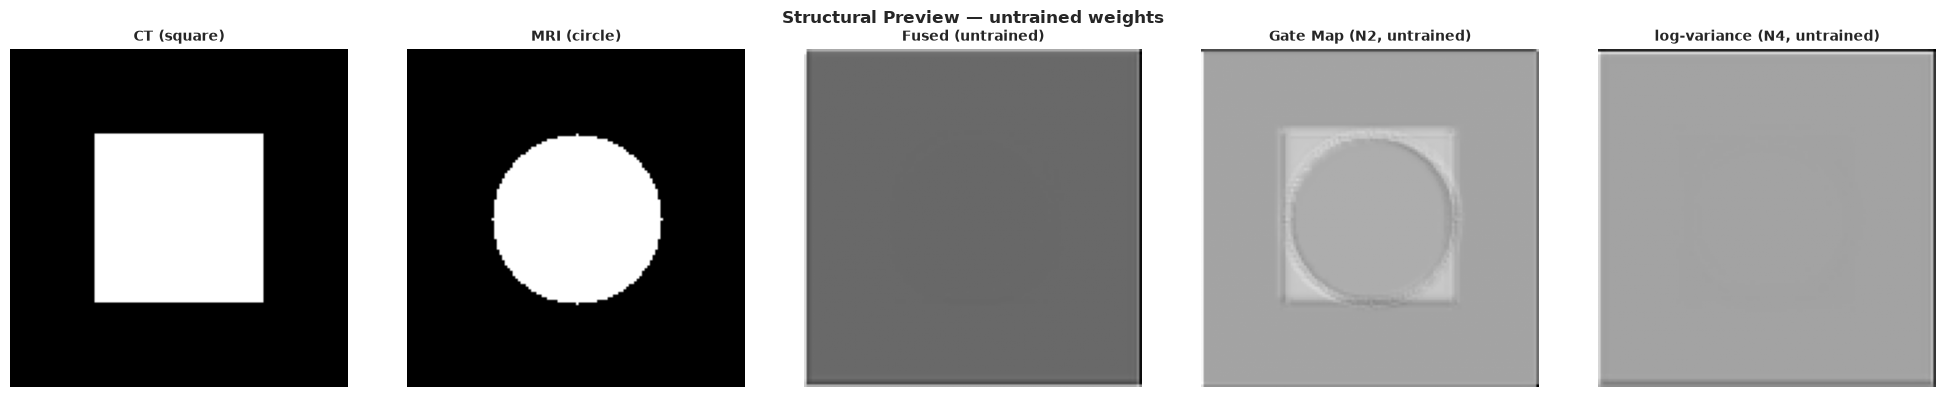

theta at init (should be exactly identity):
 [[1. 0. 0.]
 [0. 1. 0.]]


37917

In [ ]:
# ============================================================================
# CELL 14 — STRUCTURAL PREVIEW (untrained weights)
# Confirms the three heads produce sane, differently-shaped outputs and that
# theta starts at identity, before a single gradient step has been taken.
# ============================================================================
h, w, _ = TEST_SHAPE
demo_a = np.zeros((1, h, w, 1), dtype="float32")
demo_b = np.zeros((1, h, w, 1), dtype="float32")
demo_a[0, h // 4:3 * h // 4, w // 4:3 * w // 4, 0] = 1.0
yy, xx = np.ogrid[:h, :w]
demo_b[0][(xx - w // 2) ** 2 + (yy - h // 2) ** 2 <= (h // 4) ** 2] = 1.0

_g = build_generator(TEST_SHAPE, base_filters=16).to(DEVICE).eval()
with torch.no_grad():
    f_img, lv, gm, th = _g(to_nchw(demo_a, DEVICE), to_nchw(demo_b, DEVICE))
f_img, lv, gm, th = to_nhwc(f_img), to_nhwc(lv), to_nhwc(gm), th.cpu().numpy()

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, img, t in zip(axes,
        [demo_a[0], demo_b[0], f_img[0], gm[0], lv[0]],
        ["CT (square)", "MRI (circle)", "Fused (untrained)",
         "Gate Map (N2, untrained)", "log-variance (N4, untrained)"]):
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(t, fontsize=10, fontweight="bold"); ax.axis("off")
plt.suptitle("Structural Preview — untrained weights", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig2d_preview_untrained.png", dpi=150); plt.show()
print("theta at init (should be exactly identity):\n", th[0])
del _g; gc.collect()


In [ ]:
# ============================================================================
# CELL 15 — PART 3: LOAD DATA
# Arrays stay uint8 NHWC in RAM (or memory-mapped). The permutation to NCHW and
# the /255 normalisation happen once per batch, on the GPU.
# ============================================================================
with open(f"{DATA_DIR}/config.txt") as f:
    cfg = dict(line.strip().split("=") for line in f if line.strip())
RESOLUTIONS = eval(cfg["RESOLUTIONS"])
ABLATION_RES = RESOLUTIONS[0]

_sp = np.load(f"{DATA_DIR}/split_indices.npz")
TRAIN_IDX, VAL_IDX, TEST_IDX = _sp["train"], _sp["val"], _sp["test"]

datasets = {}
for res in RESOLUTIONS:
    datasets[res] = (
        np.load(f"{DATA_DIR}/A_{res}.npy",   mmap_mode="r"),   # memmap: 512x512 is 1.4 GB each
        np.load(f"{DATA_DIR}/B_{res}.npy",   mmap_mode="r"),
        np.load(f"{DATA_DIR}/Y_{res}.npy"),
        np.load(f"{DATA_DIR}/REF_{res}.npy", mmap_mode="r"),
    )
    print(f"[{res}] A={datasets[res][0].shape} dtype={datasets[res][0].dtype} (memmapped)")

BASE_FILTERS = 32
EPOCHS = MAX_EPOCHS
print(f"\nEPOCHS={EPOCHS} BASE_FILTERS={BASE_FILTERS} ABLATION_RES={ABLATION_RES}")
print(f"split: train={len(TRAIN_IDX)} val={len(VAL_IDX)} test={len(TEST_IDX)}")


[256] A=(4318, 256, 256, 1) dtype=uint8 (memmapped)
[512] A=(4318, 512, 512, 1) dtype=uint8 (memmapped)

EPOCHS=300 BASE_FILTERS=32 ABLATION_RES=256
split: train=2935 val=519 test=864


In [ ]:
# ============================================================================
# CELL 16 — METRICS  (framework-independent, unchanged)
# Everything is normalised to float [0,1] before SSIM/PSNR, so data_range=1.0
# is actually true.
#
# The reference-free fusion metrics are the headline: SSIM/PSNR against
# REF=(A+B)/2 only measures "how well did the model learn to average its own
# inputs". Q^AB/F, mutual information, entropy, SD and spatial frequency are
# what the fusion literature uses when no ground-truth fused image exists.
# ============================================================================
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, roc_curve, auc)
from skimage.metrics import structural_similarity as ssim_metric
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from scipy import stats


def to_unit(x):
    """uint8 [0,255] or float -> float64 [0,1]."""
    x = np.asarray(x)
    return (x.astype("float64") / 255.0) if x.dtype == np.uint8 else x.astype("float64")


def _sobel(img):
    gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    return np.sqrt(gx ** 2 + gy ** 2), np.arctan2(gy, gx + 1e-12)


def qabf(a_img, b_img, f_img):
    """Xydeas & Petrovic gradient-based fusion quality Q^AB/F in [0,1]."""
    Tg, kg, sg = 0.9994, -15.0, 0.5
    Ta, ka, sa = 0.9879, -22.0, 0.8
    gA, aA = _sobel(a_img); gB, aB = _sobel(b_img); gF, aF = _sobel(f_img)

    def q(g1, a1):
        G = np.clip(np.where(g1 > gF, gF / (g1 + 1e-12), g1 / (gF + 1e-12)), 0, 1)
        A = np.clip(1.0 - np.abs(a1 - aF) / (np.pi / 2), 0, 1)
        return (Tg / (1 + np.exp(kg * (G - sg)))) * (Ta / (1 + np.exp(ka * (A - sa))))

    wA, wB = gA, gB
    return float((q(gA, aA) * wA + q(gB, aB) * wB).sum() / (wA.sum() + wB.sum() + 1e-12))


def _mutual_information(x, y, bins=64):
    h, _, _ = np.histogram2d(x.ravel(), y.ravel(), bins=bins, range=[[0, 1], [0, 1]])
    p = h / (h.sum() + 1e-12)
    px, py = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
    nz = p > 0
    return float((p[nz] * np.log2(p[nz] / ((px @ py)[nz] + 1e-12))).sum())


def _entropy(img, bins=256):
    h, _ = np.histogram(img, bins=bins, range=(0, 1))
    p = h / (h.sum() + 1e-12); p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def _spatial_frequency(img):
    rf = np.sqrt(np.mean(np.diff(img, axis=1) ** 2))
    cf = np.sqrt(np.mean(np.diff(img, axis=0) ** 2))
    return float(np.sqrt(rf ** 2 + cf ** 2))


def classification_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (np.asarray(y_prob).ravel() >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "sensitivity": recall_score(y_true, y_pred, zero_division=0),
            "specificity": tn / (tn + fp) if (tn + fp) else 0.0}


def fusion_quality_metrics(fused, reference, src_a, src_b, max_samples=400):
    """fused: float [0,1]. reference/src_a/src_b: uint8 or float, auto-normalised."""
    n = min(len(fused), max_samples)
    ssim_r, psnr_r, mse_r, q_ab, mi, en, sd, sf, ssim_src = ([] for _ in range(9))
    for i in range(n):
        f = to_unit(fused[i]).squeeze()
        r = to_unit(reference[i]).squeeze()
        a = to_unit(src_a[i]).squeeze()
        b = to_unit(src_b[i]).squeeze()
        ssim_r.append(ssim_metric(r, f, data_range=1.0))
        psnr_r.append(psnr_metric(r, f, data_range=1.0))
        mse_r.append(float(np.mean((f - r) ** 2)))
        q_ab.append(qabf(a, b, f))
        mi.append(_mutual_information(a, f) + _mutual_information(b, f))
        en.append(_entropy(f)); sd.append(float(f.std())); sf.append(_spatial_frequency(f))
        ssim_src.append(0.5 * (ssim_metric(a, f, data_range=1.0) +
                               ssim_metric(b, f, data_range=1.0)))
    m = lambda v: float(np.mean(v))
    return {"qabf": m(q_ab), "mi": m(mi), "entropy": m(en), "sd": m(sd), "sf": m(sf),
            "ssim_src": m(ssim_src), "ssim_ref": m(ssim_r), "psnr_ref": m(psnr_r),
            "mse_ref": m(mse_r)}


def per_sample_qabf(fused, src_a, src_b):
    return [qabf(to_unit(a).squeeze(), to_unit(b).squeeze(), to_unit(f).squeeze())
            for f, a, b in zip(fused, src_a, src_b)]


print("Metrics ready (Q^AB/F, MI, entropy, SD, SF + reference-based sanity checks).")


Metrics ready (Q^AB/F, MI, entropy, SD, SF + reference-based sanity checks).


In [ ]:
# ============================================================================
# CELL 17 — TDNNovelGAN  (PyTorch, multi-GPU)
#
# WHAT CHANGED FROM THE TF VERSION, AND WHY
#
# 1. ONE forward, THREE gradient sets. The TF code used a persistent GradientTape
#    and called tape.gradient() three times. The literal PyTorch equivalent is
#    torch.autograd.grad(loss, params, retain_graph=True), which takes gradients
#    w.r.t. a chosen subset of parameters without polluting the others. That is
#    what is done below -- NOT three separate .backward() calls, which would
#    either need three forward passes or would cross-contaminate .grad buffers.
#
# 2. ALL grads are computed BEFORE any optimizer.step(). This is mandatory in
#    PyTorch, not stylistic: the autograd graph holds references to the live
#    parameter tensors, so stepping an optimizer first and differentiating
#    afterwards silently uses updated weights (or raises a version-counter
#    error). TF's tape did not have this hazard because it recorded values.
#
# 3. NO 1/N_REPLICAS loss scaling. MirroredStrategy SUM-reduces gradients across
#    replicas, so the TF code had to pre-scale. DataParallel gathers the forward
#    outputs onto cuda:0 and the loss is computed once over the whole global
#    batch, so the mean is already correct. Logged losses are therefore directly
#    comparable to both the old TF logs and to single-GPU runs.
#
# 4. Logits, not probabilities. binary_cross_entropy_with_logits everywhere.
#
# 5. Manual batching instead of tf.data. For in-RAM uint8 tensors a DataLoader's
#    worker processes cost more than they save; a shuffled index permutation
#    over one pre-staged contiguous CPU tensor is faster and fully reproducible.
#    drop_last is implicit (the tail of the permutation is skipped), which keeps
#    per-replica batches equal for BatchNorm -- the same reason the TF code used
#    drop_remainder=True.
#
# 6. Early stopping restores best weights via copy.deepcopy(state_dict()), the
#    direct analogue of get_weights()/set_weights().
#
# Inference (predict_fused / _validate / MC-dropout) stays single-device on
# cuda:0 -- it is a small fraction of wall time and keeps Part 4 simple.
# ============================================================================
def _unwrap(m):
    """DataParallel-safe access to the underlying module."""
    return m.module if isinstance(m, nn.DataParallel) else m


@torch.no_grad()
def gen_forward(gen, use_uncertainty, a, b, batch_size=8, training=False, mc=False,
                device=None):
    """Batched generator inference on ONE device. Takes NHWC numpy, returns NHWC
    numpy -- so every downstream figure and metric call is layout-agnostic."""
    device = device or DEVICE
    gen = _unwrap(gen)
    was_training = gen.training
    gen.train(training)
    set_mc_dropout(gen, mc)

    fs, lvs, gms, ths = [], [], [], []
    for s in range(0, len(a), batch_size):
        ta = to_nchw(a[s:s + batch_size], device)
        tb = to_nchw(b[s:s + batch_size], device)
        f, lv, gm, th = gen(ta, tb)
        fs.append(to_nhwc(f)); gms.append(to_nhwc(gm)); ths.append(th.cpu().numpy())
        if use_uncertainty and lv is not None:
            lvs.append(to_nhwc(lv))

    set_mc_dropout(gen, False)
    gen.train(was_training)
    return (np.concatenate(fs),
            np.concatenate(lvs) if lvs else None,
            np.concatenate(gms), np.concatenate(ths))


@torch.no_grad()
def predict_proba(classifier, images_nhwc, batch_size=16, device=None):
    """Replacement for keras `model.predict`. Returns sigmoid probabilities."""
    device = device or DEVICE
    clf = _unwrap(classifier).eval()
    out = []
    for s in range(0, len(images_nhwc), batch_size):
        x = to_nchw(images_nhwc[s:s + batch_size], device)
        out.append(torch.sigmoid(clf(x)).cpu().numpy())
    return np.concatenate(out)


class TDNNovelGAN:
    def __init__(self, input_shape, base_filters=32,
                 use_adversarial=True, use_saliency=True, use_temporal_decomp=True,
                 use_alignment=True, use_adaptive_gate=True, use_uncertainty=True,
                 use_joint_diagnostic=True,
                 lambda_adv=0.1, lambda_diag=0.3, lambda_unc=0.01,
                 lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY, device=None):
        self.input_shape = input_shape                 # TF-style (H, W, C)
        self.use_adversarial = use_adversarial
        self.use_uncertainty = use_uncertainty
        self.use_joint_diagnostic = use_joint_diagnostic
        self.lambda_adv, self.lambda_diag, self.lambda_unc = lambda_adv, lambda_diag, lambda_unc
        self.device = device or DEVICE

        self.generator = build_generator(
            input_shape, base_filters,
            use_saliency=use_saliency, use_temporal_decomp=use_temporal_decomp,
            use_alignment=use_alignment, use_adaptive_gate=use_adaptive_gate,
            use_uncertainty=use_uncertainty).to(self.device)
        self.discriminator = build_discriminator(input_shape, base_filters).to(self.device)
        self.classifier    = build_classifier(input_shape, base_filters).to(self.device)

        # DataParallel wrappers are used ONLY in the train step. `self.generator`
        # etc. stay as the raw modules, so state_dict keys have no "module."
        # prefix and Part 4 can load them without any renaming.
        if USE_DATA_PARALLEL:
            # output_device must match self.device, or the gathered tensors land
            # on cuda:0 while the targets sit elsewhere.
            _ids = [self.device.index] + [i for i in range(torch.cuda.device_count())
                                          if i != self.device.index]
            _dp = lambda m: nn.DataParallel(m, device_ids=_ids,
                                            output_device=self.device.index)
            self._g, self._d, self._c = _dp(self.generator), _dp(self.discriminator), _dp(self.classifier)
        else:
            self._g, self._d, self._c = self.generator, self.discriminator, self.classifier

        self.g_opt = AdamW(self.generator.parameters(),     lr=lr,
                           betas=(0.5, 0.999), weight_decay=weight_decay)
        self.d_opt = AdamW(self.discriminator.parameters(), lr=lr,
                           betas=(0.5, 0.999), weight_decay=weight_decay)
        self.c_opt = AdamW(self.classifier.parameters(),    lr=lr,
                           betas=(0.9, 0.999), weight_decay=weight_decay)

        self._g_params = [p for p in self.generator.parameters()     if p.requires_grad]
        self._d_params = [p for p in self.discriminator.parameters() if p.requires_grad]
        self._c_params = [p for p in self.classifier.parameters()    if p.requires_grad]

    # ------------------------------------------------------------------ utils
    @staticmethod
    def _assign_grads(params, grads):
        for p, gr in zip(params, grads):
            p.grad = gr

    def _train_mode(self, flag=True):
        for m in (self.generator, self.discriminator, self.classifier):
            m.train(flag)

    # ------------------------------------------------------------- train step
    def _train_step(self, a_u8, b_u8, ref_u8, y):
        dev = self.device
        a   = a_u8.to(dev, non_blocking=True).float().div_(255.0)
        b   = b_u8.to(dev, non_blocking=True).float().div_(255.0)
        ref = ref_u8.to(dev, non_blocking=True).float().div_(255.0)
        y   = y.to(dev, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE,
                            enabled=USE_AMP and dev.type == "cuda"):
            fused, log_var, gate_map, theta = self._g(a, b)

            if self.use_adversarial:
                real_logit = self._d(ref)
                fake_logit = self._d(fused)
                d_loss = (F.binary_cross_entropy_with_logits(
                              real_logit, torch.ones_like(real_logit)) +
                          F.binary_cross_entropy_with_logits(
                              fake_logit, torch.zeros_like(fake_logit)))
                g_adv_loss = F.binary_cross_entropy_with_logits(
                    fake_logit, torch.ones_like(fake_logit))
            else:
                d_loss = torch.zeros((), device=dev)
                g_adv_loss = torch.zeros((), device=dev)

            if self.use_uncertainty:
                # Heteroscedastic NLL (Kendall & Gal). log_var is already clamped
                # inside the generator, so exp(-log_var) cannot overflow.
                precision = torch.exp(-log_var)
                recon_loss = torch.mean(0.5 * precision * (fused - ref) ** 2 + 0.5 * log_var)
                unc_reg = torch.mean(log_var ** 2)
            else:
                recon_loss = torch.mean(torch.abs(fused - ref))
                unc_reg = torch.zeros((), device=dev)

            # NOVELTY 1: with joint training the diagnostic gradient flows back
            # THROUGH the fused image into the generator. Without it, the fused
            # image is detached and the classifier is a passive read-out.
            diag_logit = self._c(fused if self.use_joint_diagnostic else fused.detach())
            diag_loss = F.binary_cross_entropy_with_logits(diag_logit, y)

            g_loss = recon_loss + self.lambda_adv * g_adv_loss + self.lambda_unc * unc_reg
            if self.use_joint_diagnostic:
                g_loss = g_loss + self.lambda_diag * diag_loss

        # --- all gradients first, then all steps (see note 2 in the header) ---
        d_grads = (torch.autograd.grad(d_loss, self._d_params, retain_graph=True,
                                       allow_unused=True)
                   if self.use_adversarial else None)
        g_grads = torch.autograd.grad(g_loss, self._g_params, retain_graph=True,
                                      allow_unused=True)
        c_grads = torch.autograd.grad(diag_loss, self._c_params, allow_unused=True)

        if self.use_adversarial:
            self.d_opt.zero_grad(set_to_none=True)
            self._assign_grads(self._d_params, d_grads)
            self.d_opt.step()

        self.g_opt.zero_grad(set_to_none=True)
        self._assign_grads(self._g_params, g_grads)
        self.g_opt.step()

        self.c_opt.zero_grad(set_to_none=True)
        self._assign_grads(self._c_params, c_grads)
        self.c_opt.step()

        return {"g_loss": float(g_loss.detach()), "d_loss": float(d_loss.detach()),
                "recon_loss": float(recon_loss.detach()), "diag_loss": float(diag_loss.detach())}

    # ------------------------------------------------------------- validation
    @torch.no_grad()
    def _validate(self, a_val, b_val, ref_val, y_val, batch_size):
        self._train_mode(False)
        recon, diag, n = 0.0, 0.0, 0
        for s in range(0, len(a_val), batch_size):
            e = s + batch_size
            a = to_nchw(a_val[s:e], self.device)
            b = to_nchw(b_val[s:e], self.device)
            ref = to_nchw(ref_val[s:e], self.device)
            y = torch.as_tensor(np.asarray(y_val[s:e], dtype="float32"), device=self.device)
            fused = self.generator(a, b)[0]
            k = fused.shape[0]
            # val_recon is ALWAYS L1, regardless of use_uncertainty, so the
            # curves stay comparable across ablation variants.
            recon += float(torch.mean(torch.abs(fused - ref))) * k
            diag  += float(F.binary_cross_entropy_with_logits(self.classifier(fused), y)) * k
            n += k
        self._train_mode(True)
        return recon / n, diag / n

    # -------------------------------------------------------------------- fit
    def fit(self, a_tr, b_tr, ref_tr, y_tr, a_val, b_val, ref_val, y_val,
            epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=1):
        """batch_size is the GLOBAL batch (split across GPUs by DataParallel)."""
        nrep = N_REPLICAS if USE_DATA_PARALLEL else 1
        if batch_size % nrep or batch_size // nrep < 2:
            batch_size = max(2 * nrep, (batch_size // nrep) * nrep)
            if verbose:
                print(f"  [multi-gpu] adjusted global batch to {batch_size}")

        # Pre-stage each split once as a contiguous NCHW uint8 CPU tensor.
        A_t   = nchw_uint8(a_tr)
        B_t   = nchw_uint8(b_tr)
        REF_t = nchw_uint8(ref_tr)
        Y_t   = torch.as_tensor(np.asarray(y_tr, dtype="float32"))

        n = A_t.shape[0]
        n_batches = n // batch_size                    # implicit drop_last
        if n_batches == 0:
            raise ValueError(f"batch_size={batch_size} exceeds training set size {n}")

        gen_cpu = torch.Generator().manual_seed(SEED)
        history = {k: [] for k in ["g_loss", "d_loss", "recon_loss", "diag_loss",
                                   "val_recon_loss", "val_diag_loss"]}
        best_val, wait = np.inf, 0
        best_g = best_c = best_d = None

        self._train_mode(True)
        for epoch in range(epochs):
            perm = torch.randperm(n, generator=gen_cpu)
            acc = {k: [] for k in ["g_loss", "d_loss", "recon_loss", "diag_loss"]}

            for bi in range(n_batches):
                idx = perm[bi * batch_size:(bi + 1) * batch_size]
                losses = self._train_step(A_t[idx], B_t[idx], REF_t[idx], Y_t[idx])
                for k in acc:
                    acc[k].append(losses[k])

            val_recon, val_diag = self._validate(
                a_val, b_val, ref_val, y_val, max(2, batch_size // nrep))
            for k in acc:
                history[k].append(float(np.mean(acc[k])) if acc[k] else 0.0)
            history["val_recon_loss"].append(val_recon)
            history["val_diag_loss"].append(val_diag)

            if verbose and (epoch % max(1, epochs // 40) == 0 or epoch == epochs - 1):
                print(f"  epoch {epoch+1}/{epochs} | g={history['g_loss'][-1]:.4f} "
                      f"d={history['d_loss'][-1]:.4f} val_recon={val_recon:.4f} "
                      f"val_diag={val_diag:.4f}")

            monitor = val_recon + val_diag
            if monitor < best_val - 1e-4:
                best_val, wait = monitor, 0
                best_g = copy.deepcopy(self.generator.state_dict())
                best_c = copy.deepcopy(self.classifier.state_dict())
                best_d = copy.deepcopy(self.discriminator.state_dict())
            else:
                wait += 1
                if wait >= patience:
                    if verbose:
                        print(f"  early stop at epoch {epoch+1} (best monitor={best_val:.4f})")
                    break

        if best_g is not None:
            self.generator.load_state_dict(best_g)
            self.classifier.load_state_dict(best_c)
            self.discriminator.load_state_dict(best_d)
            if verbose:
                print("  restored best weights.")

        del A_t, B_t, REF_t, Y_t
        gc.collect()
        return history

    # -------------------------------------------------------------- inference
    def predict_fused(self, a, b, batch_size=8, mc=False):
        return gen_forward(self.generator, self.use_uncertainty, a, b,
                           batch_size=batch_size, training=False, mc=mc,
                           device=self.device)

    def predict_proba(self, images_nhwc, batch_size=16):
        return predict_proba(self.classifier, images_nhwc, batch_size, self.device)

    def mc_dropout_uncertainty(self, a, b, n_passes=20, batch_size=8):
        preds = [self.predict_fused(a, b, batch_size=batch_size, mc=True)[0]
                 for _ in range(n_passes)]
        preds = np.stack(preds, 0)
        return preds.mean(0), preds.var(0)


print(f"TDNNovelGAN ready "
      f"({'DataParallel x %d GPUs' % N_REPLICAS if USE_DATA_PARALLEL else str(DEVICE)}).")


TDNNovelGAN ready (cuda:1).


In [ ]:
# ============================================================================
# CELL 18 — ABLATION
# Each row is a genuinely distinct flag dict. N5 (Grad-CAM) is post-hoc and has
# no training flag, so the sixth row varies `use_adversarial` instead.
# ============================================================================
A, B, Y, REF = datasets[ABLATION_RES]

def take(arr, ix):
    return np.asarray(arr[np.sort(ix)])

A_tr,  B_tr,  REF_tr,  Y_tr  = (take(A, TRAIN_IDX), take(B, TRAIN_IDX),
                                take(REF, TRAIN_IDX), Y[np.sort(TRAIN_IDX)])
A_val, B_val, REF_val, Y_val = (take(A, VAL_IDX), take(B, VAL_IDX),
                                take(REF, VAL_IDX), Y[np.sort(VAL_IDX)])
A_te,  B_te,  REF_te,  Y_te  = (take(A, TEST_IDX), take(B, TEST_IDX),
                                take(REF, TEST_IDX), Y[np.sort(TEST_IDX)])
print(f"train={len(A_tr)} val={len(A_val)} test={len(A_te)}")

FULL = dict(use_adversarial=True, use_saliency=True, use_temporal_decomp=True,
            use_alignment=True, use_adaptive_gate=True, use_uncertainty=True,
            use_joint_diagnostic=True)

ablation_variants = {
    "Baseline TDN":            {**FULL, "use_alignment": False, "use_adaptive_gate": False,
                                "use_uncertainty": False, "use_joint_diagnostic": False},
    "+ N1 Joint-Diagnostic":   {**FULL, "use_alignment": False, "use_adaptive_gate": False,
                                "use_uncertainty": False},
    "+ N2 Adaptive Gate":      {**FULL, "use_alignment": False, "use_uncertainty": False},
    "+ N3 Spatial Alignment":  {**FULL, "use_uncertainty": False},
    "Full TDN-Novel":          {**FULL},
    "Full - Adversarial":      {**FULL, "use_adversarial": False},
}

# ---------------------------------------------------------------------------
# Recognising an OOM. CUDA reports memory exhaustion under several different
# messages depending on WHICH allocation failed, and only one of them says
# "out of memory". The cuDNN one is the nastiest: when the algorithm finder
# cannot allocate workspace for any candidate engine it raises
#     RuntimeError: FIND was unable to find an engine to execute this computation
# which looks like an unsupported-operation bug but is really memory pressure.
# Matching only on "out of memory" lets that escape the handler and kill the
# whole ablation loop instead of skipping one variant.
# ---------------------------------------------------------------------------
OOM_ERRORS = (getattr(torch.cuda, "OutOfMemoryError", RuntimeError), RuntimeError)

_OOM_SIGNS = (
    "out of memory",
    "unable to find an engine",          # cuDNN v8 finder: no workspace available
    "cudnn_status_alloc_failed",
    "cudnn_status_not_supported",        # also emitted when workspace is refused
    "cublas_status_alloc_failed",
    "not enough memory",
    "failed to allocate",
)


def is_oom(err):
    return any(sign in str(err).lower() for sign in _OOM_SIGNS)

trained_models, ablation_histories, ablation_rows = {}, {}, []

for name, flags in ablation_variants.items():
    print(f"\n{'='*80}\nTraining: {name}\n{'='*80}")
    try:
        gan = TDNNovelGAN(input_shape=(ABLATION_RES, ABLATION_RES, 1),
                          base_filters=BASE_FILTERS, lr=LEARNING_RATE, **flags)
        hist = gan.fit(A_tr, B_tr, REF_tr, Y_tr, A_val, B_val, REF_val, Y_val,
                       epochs=EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=1)

        fused_te, _, _, _ = gan.predict_fused(A_te, B_te)
        fq  = fusion_quality_metrics(fused_te, REF_te, A_te, B_te)
        clf = classification_metrics(Y_te.ravel(), gan.predict_proba(fused_te, batch_size=16))

        ablation_rows.append({"Variant": name, **clf, **fq})
        trained_models[name] = gan
        ablation_histories[name] = hist
        print({k: round(v, 4) for k, v in ablation_rows[-1].items() if k != "Variant"})

    except OOM_ERRORS as e:
        if not is_oom(e):
            raise
        print(f"[SKIPPED] {name}: GPU out of memory.")
        print(f"          {str(e).splitlines()[-1][:160]}")
        print(f"          Needed ~{activation_budget():.1f} GiB/GPU of activations. "
              f"Lower BATCH_SIZE or set USE_AMP=True in CELL 8.")
        gan = None
        torch.cuda.empty_cache()
    finally:
        gc.collect()

if ablation_rows:
    ablation_df = pd.DataFrame(ablation_rows).set_index("Variant").round(4)
    print("\nTable 2 — Progressive Novelty Ablation")
    print(ablation_df)
else:
    ablation_df = pd.DataFrame()
    print("\nNo variant completed -- check GPU memory / batch size.")


train=2935 val=519 test=864

Training: Baseline TDN
  epoch 1/300 | g=0.1073 d=1.3860 val_recon=0.0155 val_diag=0.4062
  epoch 8/300 | g=0.0809 d=1.3876 val_recon=0.0103 val_diag=0.1632
  epoch 15/300 | g=0.0798 d=1.3869 val_recon=0.0074 val_diag=0.1116
  epoch 22/300 | g=0.0787 d=1.3860 val_recon=0.0048 val_diag=0.1025
  epoch 29/300 | g=0.0789 d=1.3868 val_recon=0.0043 val_diag=0.0921
  epoch 36/300 | g=0.0783 d=1.3866 val_recon=0.0055 val_diag=0.1316
  epoch 43/300 | g=0.0776 d=1.3879 val_recon=0.0038 val_diag=0.1073
  epoch 50/300 | g=0.0775 d=1.3866 val_recon=0.0044 val_diag=0.1464
  epoch 57/300 | g=0.0779 d=1.3869 val_recon=0.0087 val_diag=0.1192
  epoch 64/300 | g=0.0776 d=1.3866 val_recon=0.0042 val_diag=0.0936
  epoch 71/300 | g=0.0770 d=1.3878 val_recon=0.0035 val_diag=0.0942
  early stop at epoch 71 (best monitor=0.0850)
  restored best weights.
{'accuracy': 0.978, 'precision': 0.9724, 'sensitivity': 0.9871, 'specificity': np.float64(0.9675), 'qabf': 0.3676, 'mi': 2.9146, '

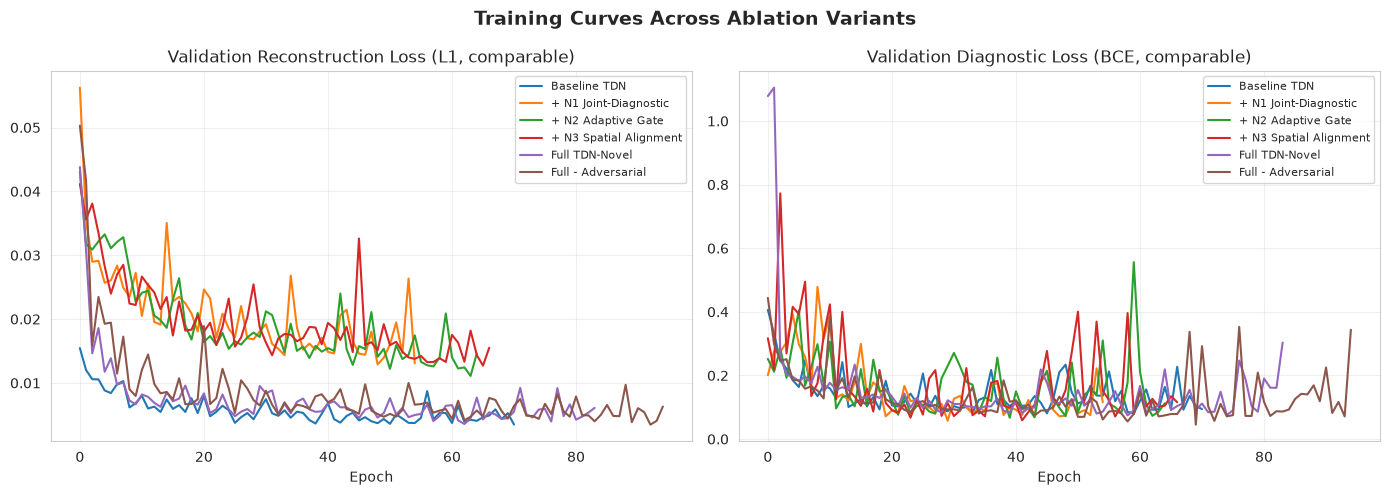

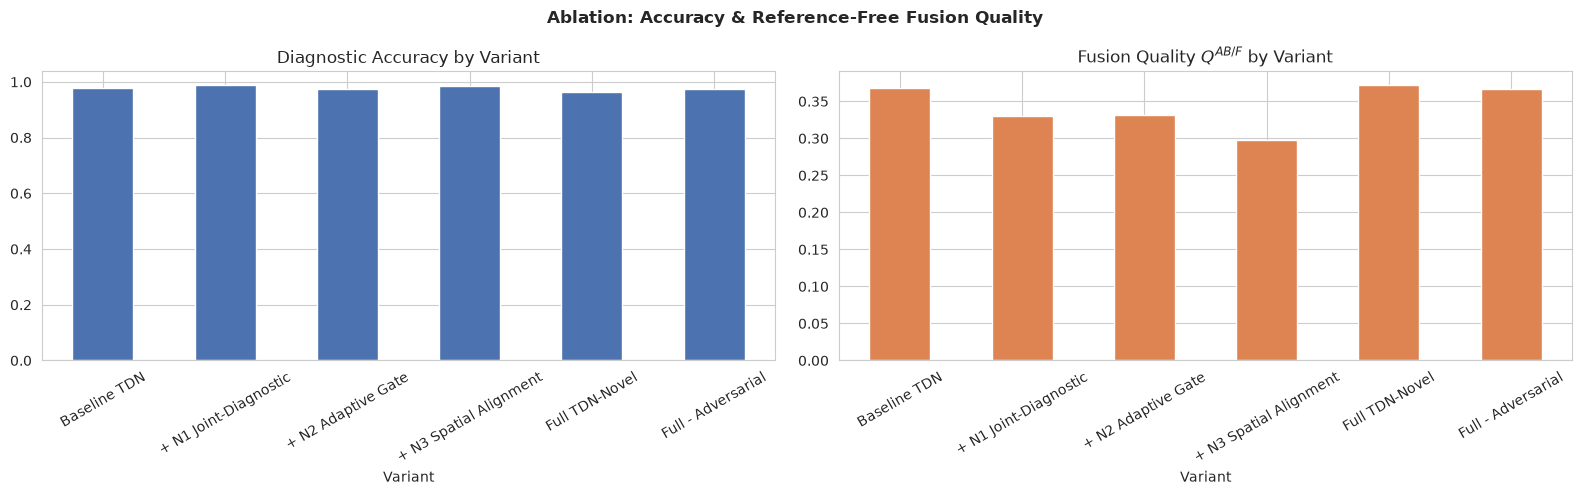

In [ ]:
# ============================================================================
# CELL 19 — TRAINING CURVES
# NOTE: g_loss is NOT comparable across rows, because recon_loss is L1 when
# use_uncertainty=False and heteroscedastic NLL when True. val_recon_loss is
# always L1, so panels 1 and 2 are the comparable ones.
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, hist in ablation_histories.items():
    axes[0].plot(hist["val_recon_loss"], label=name)
    axes[1].plot(hist["val_diag_loss"],  label=name)
axes[0].set_title("Validation Reconstruction Loss (L1, comparable)")
axes[1].set_title("Validation Diagnostic Loss (BCE, comparable)")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.suptitle("Training Curves Across Ablation Variants", fontweight="bold", fontsize=14)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig3_training_curves.png", dpi=180); plt.show()

if not ablation_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    ablation_df["accuracy"].plot(kind="bar", ax=axes[0], color="#4C72B0")
    axes[0].set_title("Diagnostic Accuracy by Variant"); axes[0].tick_params(axis="x", rotation=30)
    ablation_df["qabf"].plot(kind="bar", ax=axes[1], color="#DD8452")
    axes[1].set_title("Fusion Quality $Q^{AB/F}$ by Variant"); axes[1].tick_params(axis="x", rotation=30)
    plt.suptitle("Ablation: Accuracy & Reference-Free Fusion Quality", fontweight="bold")
    plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig3b_ablation_bars.png", dpi=180); plt.show()


In [ ]:
# ============================================================================
# CELL 20 — RESOLUTION SWEEP
# ============================================================================
results_by_resolution = {}

for res in RESOLUTIONS:
    A_r, B_r, Y_r, REF_r = datasets[res]
    res_bs = BATCH_SIZE
    try:
        if res == ABLATION_RES and "Full TDN-Novel" in trained_models:
            gan = trained_models["Full TDN-Novel"]
            a_te, b_te, ref_te, y_te = A_te, B_te, REF_te, Y_te
        else:
            print(f"\n{'='*80}\nTraining Full TDN-Novel @ {res}x{res}\n{'='*80}")
            # Activation memory scales with res^2, so 512x512 needs a quarter of
            # the batch to stay inside the same budget.
            res_bs = max(2 * N_REPLICAS, BATCH_SIZE // 4) if res > 256 else BATCH_SIZE
            gan = TDNNovelGAN(input_shape=(res, res, 1), base_filters=BASE_FILTERS,
                              lr=LEARNING_RATE, **FULL)
            gan.fit(take(A_r, TRAIN_IDX), take(B_r, TRAIN_IDX), take(REF_r, TRAIN_IDX),
                    Y_r[np.sort(TRAIN_IDX)],
                    take(A_r, VAL_IDX), take(B_r, VAL_IDX), take(REF_r, VAL_IDX),
                    Y_r[np.sort(VAL_IDX)],
                    epochs=EPOCHS, batch_size=res_bs, patience=PATIENCE, verbose=1)
            trained_models[f"Full TDN-Novel @ {res}"] = gan
            a_te, b_te = take(A_r, TEST_IDX), take(B_r, TEST_IDX)
            ref_te, y_te = take(REF_r, TEST_IDX), Y_r[np.sort(TEST_IDX)]

        fused_te, _, _, _ = gan.predict_fused(a_te, b_te, batch_size=4 if res > 256 else 8)
        fq  = fusion_quality_metrics(fused_te, ref_te, a_te, b_te)
        clf = classification_metrics(y_te.ravel(), gan.predict_proba(fused_te, batch_size=8))
        results_by_resolution[res] = {"Resolution": f"{res}x{res}", **clf, **fq}
        print({k: round(v, 4) for k, v in results_by_resolution[res].items() if k != "Resolution"})

    except OOM_ERRORS as e:
        if not is_oom(e):
            raise
        print(f"[SKIPPED] {res}x{res}: GPU out of memory.")
        print(f"          {str(e).splitlines()[-1][:160]}")
        print(f"          Needed ~{activation_budget(res_bs if res != ABLATION_RES else BATCH_SIZE, res=res):.1f}"
              f" GiB/GPU of activations at this resolution.")
        gan = None
        torch.cuda.empty_cache()
    finally:
        gc.collect()

results_by_res_df = pd.DataFrame(list(results_by_resolution.values())).set_index("Resolution").round(4)
print("\nTable 3 — Full TDN-Novel by Resolution"); print(results_by_res_df)


{'accuracy': 0.9653, 'precision': 0.9637, 'sensitivity': 0.972, 'specificity': np.float64(0.9575), 'qabf': 0.3719, 'mi': 2.8687, 'entropy': 6.8928, 'sd': 0.2345, 'sf': 0.0891, 'ssim_src': 0.5811, 'ssim_ref': 0.9968, 'psnr_ref': 42.7371, 'mse_ref': 0.0001}

Training Full TDN-Novel @ 512x512
  epoch 1/300 | g=-2.0547 d=1.3833 val_recon=0.0133 val_diag=0.4670
  epoch 8/300 | g=-2.6923 d=1.3867 val_recon=0.0080 val_diag=0.1585
  epoch 15/300 | g=-2.7329 d=1.2005 val_recon=0.0051 val_diag=0.1131
  epoch 22/300 | g=-2.7917 d=1.3739 val_recon=0.0072 val_diag=0.1303
  epoch 29/300 | g=-2.8100 d=1.3890 val_recon=0.0052 val_diag=0.1050
  epoch 36/300 | g=-2.7471 d=0.9307 val_recon=0.0065 val_diag=0.1445
  epoch 43/300 | g=-2.7339 d=0.9124 val_recon=0.0078 val_diag=0.1331
  epoch 50/300 | g=-2.7058 d=0.7797 val_recon=0.0051 val_diag=0.0487
  epoch 57/300 | g=-2.7322 d=0.8239 val_recon=0.0049 val_diag=0.0890
  epoch 64/300 | g=-2.6664 d=0.5853 val_recon=0.0088 val_diag=0.0562
  epoch 71/300 | g=-2

In [ ]:
# ============================================================================
# CELL 21 — SAVE CHECKPOINTS
# PORTING NOTE: `.weights.h5` becomes `.pt` holding a state_dict. state_dicts
# are saved from the RAW modules (never the DataParallel wrapper), so the keys
# carry no "module." prefix and load cleanly on a single GPU, on CPU, or on a
# machine with a different GPU count.
# ============================================================================
saved_manifest = []
for name, gan in trained_models.items():
    safe = (name.replace(" ", "_").replace("(", "").replace(")", "")
                .replace("+", "plus").replace("@", "at").replace("-", "_"))
    gen_path = f"{CHECKPOINT_DIR}/{safe}_generator.pt"
    clf_path = f"{CHECKPOINT_DIR}/{safe}_classifier.pt"
    torch.save(_unwrap(gan.generator).state_dict(), gen_path)
    torch.save(_unwrap(gan.classifier).state_dict(), clf_path)
    saved_manifest.append({
        "name": name, "safe_name": safe, "input_shape": list(gan.input_shape),
        "base_filters": BASE_FILTERS, "flags": ablation_variants.get(name, FULL),
        "generator_weights": gen_path, "classifier_weights": clf_path,
    })
    print("Saved:", name)

with open(f"{CHECKPOINT_DIR}/manifest.json", "w") as f:
    json.dump(saved_manifest, f, indent=2)
with open(f"{CHECKPOINT_DIR}/ablation_histories.json", "w") as f:
    json.dump({n: {k: [float(x) for x in v] for k, v in h.items()}
               for n, h in ablation_histories.items()}, f)
with open(f"{CHECKPOINT_DIR}/config.txt", "w") as f:
    f.write(f"ABLATION_RES={ABLATION_RES}\nRESOLUTIONS={RESOLUTIONS}\n"
            f"BASE_FILTERS={BASE_FILTERS}\n")
if not ablation_df.empty:
    ablation_df.to_csv(f"{CHECKPOINT_DIR}/table2_ablation_results.csv")
results_by_res_df.to_csv(f"{CHECKPOINT_DIR}/table3_resolution_results.csv")

print(f"\nPart 3 complete. {len(saved_manifest)} checkpoints in {CHECKPOINT_DIR}")


Saved: Baseline TDN
Saved: + N1 Joint-Diagnostic
Saved: + N2 Adaptive Gate
Saved: + N3 Spatial Alignment
Saved: Full TDN-Novel
Saved: Full - Adversarial
Saved: Full TDN-Novel @ 512

Part 3 complete. 7 checkpoints in /home/dhrubo/Videos/plos/TDN_pipeline/checkpoints


In [ ]:
# ============================================================================
# CELL 22 — PART 4: LOAD CHECKPOINTS
# CHECKPOINT_DIR is the same variable Part 3 wrote to (CELL 2).
#
# PORTING NOTE: Keras needed a dummy forward pass before load_weights() so the
# layers were built and had weight tensors to fill. PyTorch modules allocate
# their parameters in __init__, so load_state_dict works immediately -- but you
# must construct the module with the SAME flags, since the flags decide which
# submodules exist at all. That is exactly what the manifest stores.
# `strict=True` is left on deliberately: a silent key mismatch is a bug you want
# to hear about, not paper over.
# ============================================================================
with open(f"{CHECKPOINT_DIR}/manifest.json") as f:
    manifest = json.load(f)
with open(f"{CHECKPOINT_DIR}/ablation_histories.json") as f:
    ablation_histories = json.load(f)
with open(f"{CHECKPOINT_DIR}/config.txt") as f:
    train_cfg = dict(l.strip().split("=") for l in f if l.strip())
ABLATION_RES = int(train_cfg["ABLATION_RES"])


def load_variant(entry):
    shape, bf, flags = tuple(entry["input_shape"]), entry["base_filters"], entry["flags"]
    gen = build_generator(shape, bf,
                          use_saliency=flags["use_saliency"],
                          use_temporal_decomp=flags["use_temporal_decomp"],
                          use_alignment=flags["use_alignment"],
                          use_adaptive_gate=flags["use_adaptive_gate"],
                          use_uncertainty=flags["use_uncertainty"]).to(DEVICE)
    clf = build_classifier(shape, bf).to(DEVICE)
    gen.load_state_dict(torch.load(entry["generator_weights"], map_location=DEVICE))
    clf.load_state_dict(torch.load(entry["classifier_weights"], map_location=DEVICE))
    gen.eval(); clf.eval()
    return {"generator": gen, "classifier": clf, "flags": flags, "input_shape": shape}


loaded_models = {e["name"]: load_variant(e) for e in manifest
                 if e["input_shape"][0] == ABLATION_RES}
VARIANT_NAMES = list(loaded_models.keys())
print("Loaded at ablation resolution:", VARIANT_NAMES)

FULL_KEY = "Full TDN-Novel" if "Full TDN-Novel" in loaded_models else VARIANT_NAMES[-1]


def predict_fused(entry, a, b, batch_size=8, mc=False):
    return gen_forward(entry["generator"], entry["flags"]["use_uncertainty"],
                       a, b, batch_size=batch_size, training=False, mc=mc, device=DEVICE)


Loaded at ablation resolution: ['Baseline TDN', '+ N1 Joint-Diagnostic', '+ N2 Adaptive Gate', '+ N3 Spatial Alignment', 'Full TDN-Novel', 'Full - Adversarial']


In [ ]:
# ============================================================================
# CELL 23 — RECOMPUTE TABLE 2 FROM CHECKPOINTS
# This is the reproducibility check: numbers here should match CELL 18's table.
# ============================================================================
recomputed_rows, per_sample_qabf_map, per_sample_ssim_map = [], {}, {}
for name in VARIANT_NAMES:
    entry = loaded_models[name]
    fused, _, _, _ = predict_fused(entry, A_te, B_te)
    fq  = fusion_quality_metrics(fused, REF_te, A_te, B_te)
    clf = classification_metrics(Y_te.ravel(),
                                 predict_proba(entry["classifier"], fused, batch_size=16))
    recomputed_rows.append({"Variant": name, **clf, **fq})
    per_sample_qabf_map[name] = per_sample_qabf(fused[:400], A_te[:400], B_te[:400])
    per_sample_ssim_map[name] = [
        ssim_metric(to_unit(r).squeeze(), to_unit(f).squeeze(), data_range=1.0)
        for r, f in zip(REF_te[:400], fused[:400])]

recomputed_df = pd.DataFrame(recomputed_rows).set_index("Variant").round(4)
print("Table 2 (recomputed in Part 4)")
print(recomputed_df)


Table 2 (recomputed in Part 4)
                        accuracy  precision  sensitivity  specificity    qabf  \
Variant                                                                         
Baseline TDN              0.9780     0.9724       0.9871       0.9675  0.3676   
+ N1 Joint-Diagnostic     0.9884     0.9956       0.9828       0.9950  0.3300   
+ N2 Adaptive Gate        0.9734     0.9623       0.9892       0.9550  0.3312   
+ N3 Spatial Alignment    0.9850     0.9978       0.9741       0.9975  0.2976   
Full TDN-Novel            0.9653     0.9637       0.9720       0.9575  0.3719   
Full - Adversarial        0.9745     0.9804       0.9720       0.9775  0.3667   

                            mi  entropy      sd      sf  ssim_src  ssim_ref  \
Variant                                                                       
Baseline TDN            2.9146   6.8481  0.2332  0.0887    0.5809    0.9976   
+ N1 Joint-Diagnostic   2.4349   6.9110  0.2285  0.0950    0.5604    0.9528   
+ N2

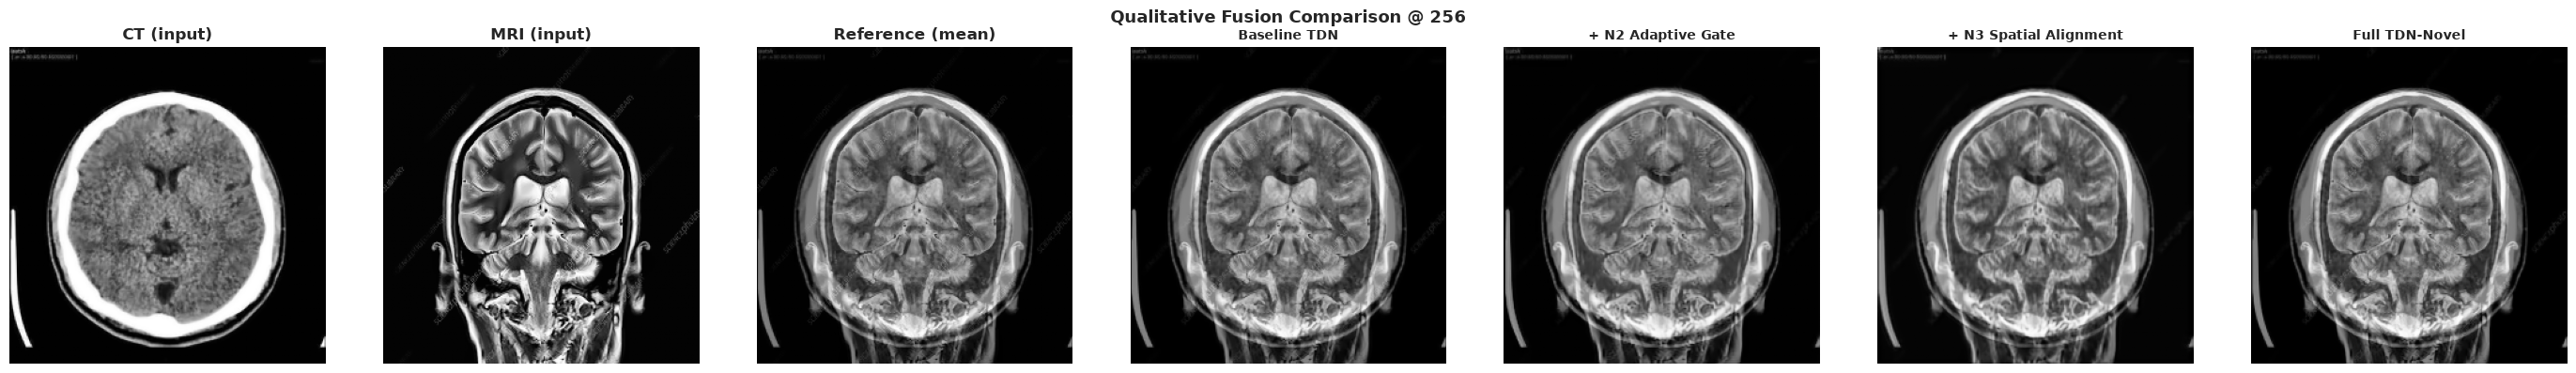

In [ ]:
# ============================================================================
# CELL 24 — QUALITATIVE FUSION COMPARISON
# ============================================================================
rng = np.random.default_rng(3)
sample_i = int(rng.choice(len(A_te)))
a_s, b_s, ref_s = A_te[sample_i:sample_i+1], B_te[sample_i:sample_i+1], REF_te[sample_i]

compare = [v for v in ["Baseline TDN", "+ N2 Adaptive Gate", "+ N3 Spatial Alignment", FULL_KEY]
           if v in loaded_models]

fig, axes = plt.subplots(1, 3 + len(compare), figsize=(4 * (3 + len(compare)), 4))
for ax, img, t in zip(axes[:3], [a_s[0], b_s[0], ref_s],
                      ["CT (input)", "MRI (input)", "Reference (mean)"]):
    ax.imshow(to_unit(img).squeeze(), cmap="gray"); ax.set_title(t, fontweight="bold"); ax.axis("off")
for k, name in enumerate(compare):
    f, _, _, _ = predict_fused(loaded_models[name], a_s, b_s)
    axes[3 + k].imshow(f[0].squeeze(), cmap="gray")
    axes[3 + k].set_title(name, fontsize=10, fontweight="bold"); axes[3 + k].axis("off")
plt.suptitle(f"Qualitative Fusion Comparison @ {ABLATION_RES}", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig4_qualitative.png", dpi=300); plt.show()


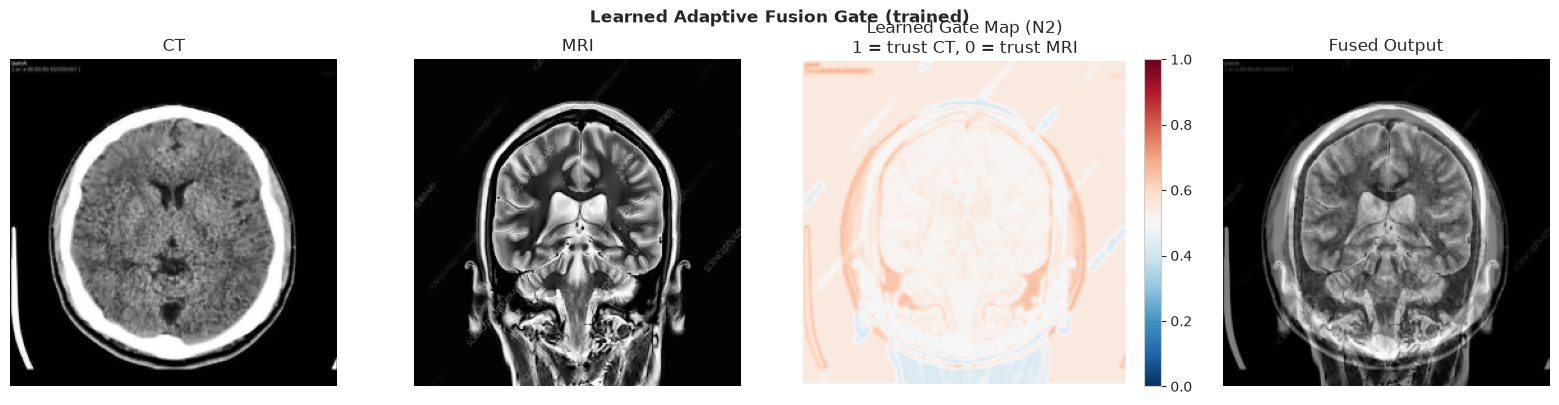

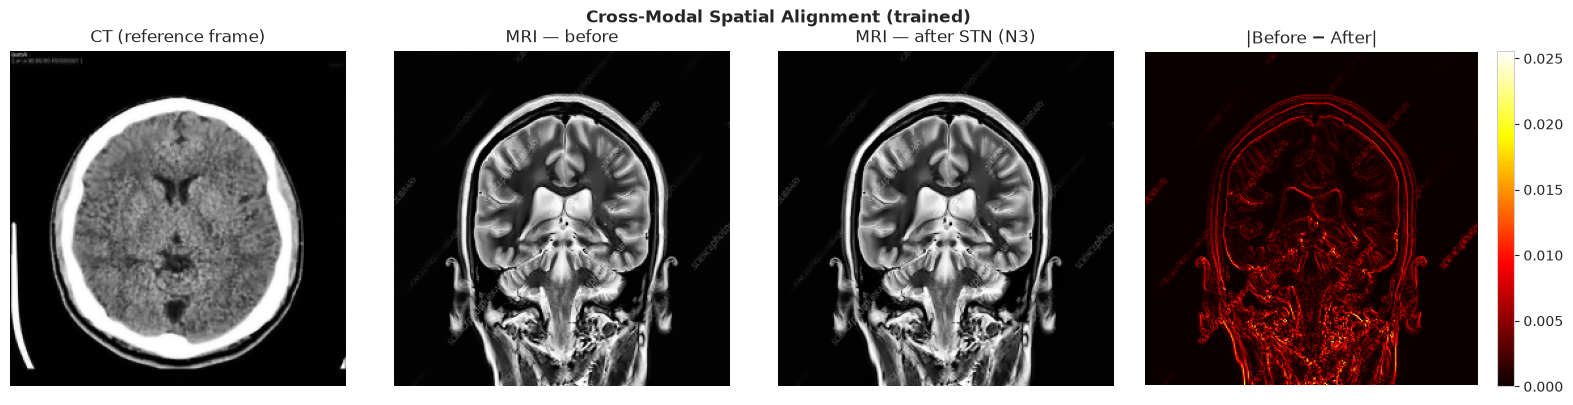

Learned affine theta:
 [[ 1.0000147e+00  1.0263458e-04  8.4018757e-05]
 [ 1.0108327e-05  9.9997807e-01 -1.0189152e-04]]


In [ ]:
# ============================================================================
# CELL 25 — N2 GATE MAP + N3 ALIGNMENT FIGURES
# The alignment panel re-applies the LEARNED theta with the standalone
# affine_warp() helper from CELL 10 -- the same F.grid_sample call the network
# used internally, so what you see is exactly what the STN did.
# ============================================================================
entry = loaded_models[FULL_KEY]
fused_g, _, gate_g, theta_g = predict_fused(entry, a_s, b_s)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(to_unit(a_s[0]).squeeze(), cmap="gray"); axes[0].set_title("CT")
axes[1].imshow(to_unit(b_s[0]).squeeze(), cmap="gray"); axes[1].set_title("MRI")
im = axes[2].imshow(gate_g[0].squeeze(), cmap="RdBu_r", vmin=0, vmax=1)
axes[2].set_title("Learned Gate Map (N2)\n1 = trust CT, 0 = trust MRI")
plt.colorbar(im, ax=axes[2], fraction=0.046)
axes[3].imshow(fused_g[0].squeeze(), cmap="gray"); axes[3].set_title("Fused Output")
for ax in axes: ax.axis("off")
plt.suptitle("Learned Adaptive Fusion Gate (trained)", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig5_gate_map.png", dpi=300); plt.show()

if entry["flags"]["use_alignment"]:
    b_f = to_unit(b_s).astype("float32")                 # NHWC float [0,1]
    b_aligned = affine_warp(b_f, theta_g)                # NHWC float [0,1]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(to_unit(a_s[0]).squeeze(), cmap="gray"); axes[0].set_title("CT (reference frame)")
    axes[1].imshow(b_f[0].squeeze(), cmap="gray");           axes[1].set_title("MRI — before")
    axes[2].imshow(b_aligned[0].squeeze(), cmap="gray");     axes[2].set_title("MRI — after STN (N3)")
    im2 = axes[3].imshow(np.abs(b_aligned[0].squeeze() - b_f[0].squeeze()), cmap="hot")
    axes[3].set_title("|Before − After|"); plt.colorbar(im2, ax=axes[3], fraction=0.046)
    for ax in axes: ax.axis("off")
    plt.suptitle("Cross-Modal Spatial Alignment (trained)", fontweight="bold")
    plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig6_alignment.png", dpi=300); plt.show()
    print("Learned affine theta:\n", theta_g[0])


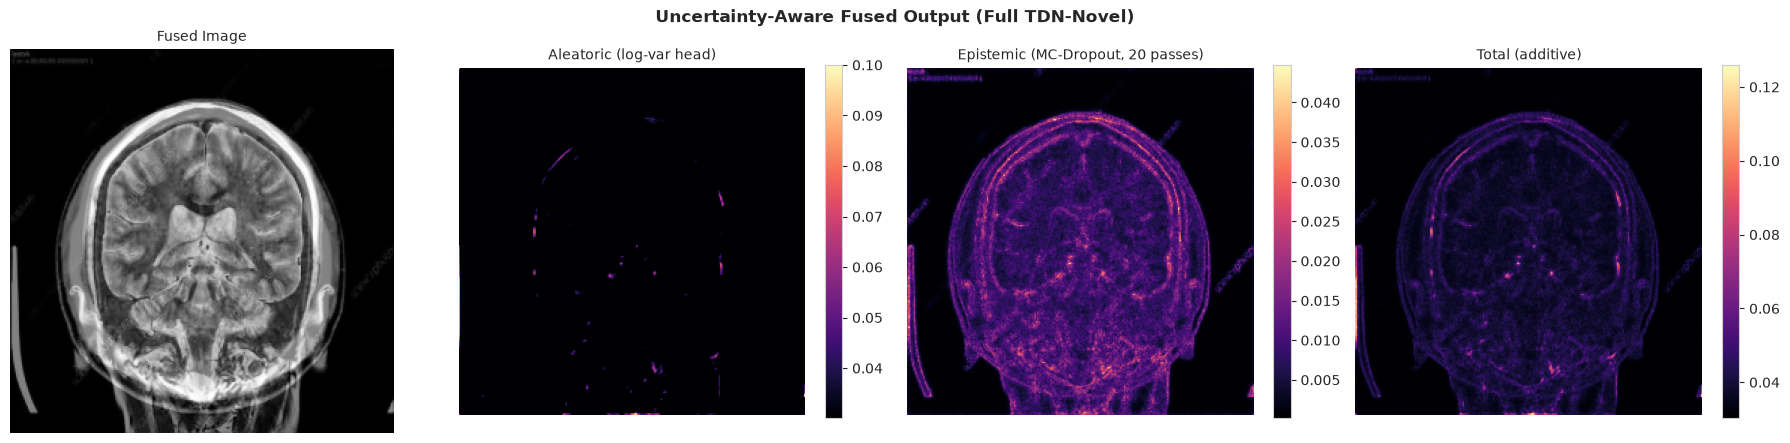

mean epistemic std: 0.00596 | mean aleatoric std: 0.03038


In [ ]:
# ============================================================================
# CELL 26 — UNCERTAINTY (N4)
# BatchNorm stays in inference mode; only MCDropout is toggled, so the epistemic
# variance reflects dropout alone. In PyTorch this matters even more than in
# Keras, because model.train() would otherwise flip BN to batch statistics AND
# enable dropout in one call -- MCDropout.mc separates the two.
# ============================================================================
entry = loaded_models[FULL_KEY]
fused_u, log_var_u, _, _ = predict_fused(entry, a_s, b_s)
aleatoric_std = np.sqrt(np.exp(log_var_u[0].squeeze())) if log_var_u is not None else None

preds = np.stack([predict_fused(entry, a_s, b_s, mc=True)[0] for _ in range(20)], 0)
epistemic_std = np.sqrt(preds.var(0)[0].squeeze())

panels = [(fused_u[0].squeeze(), "Fused Image", "gray")]
if aleatoric_std is not None:
    panels.append((aleatoric_std, "Aleatoric (log-var head)", "magma"))
panels.append((epistemic_std, "Epistemic (MC-Dropout, 20 passes)", "magma"))
if aleatoric_std is not None:
    panels.append((aleatoric_std + epistemic_std, "Total (additive)", "magma"))

fig, axes = plt.subplots(1, len(panels), figsize=(4.5 * len(panels), 4.5))
for ax, (img, t, cm) in zip(np.atleast_1d(axes), panels):
    im = ax.imshow(img, cmap=cm); ax.set_title(t, fontsize=10); ax.axis("off")
    if cm != "gray":
        plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle(f"Uncertainty-Aware Fused Output ({FULL_KEY})", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig7_uncertainty.png", dpi=300); plt.show()
print(f"mean epistemic std: {epistemic_std.mean():.5f}"
      + (f" | mean aleatoric std: {aleatoric_std.mean():.5f}" if aleatoric_std is not None else ""))


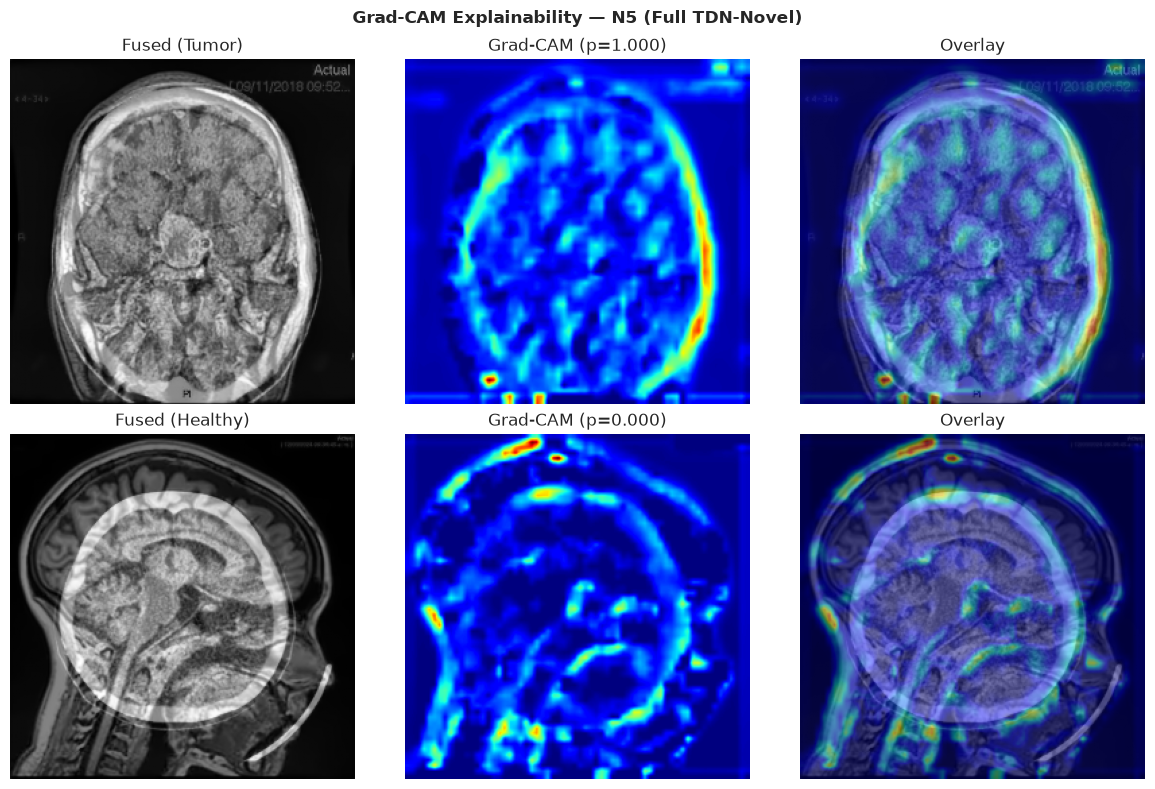

In [ ]:
# ============================================================================
# CELL 27 — GRAD-CAM (N5)
# PORTING NOTE: Keras needed a second Model tapping an intermediate layer by
# name. In PyTorch the classifier simply returns its last conv activations when
# asked (return_features=True), which is both cheaper and less fragile than
# name-based lookup. A forward hook would work too if you did not want to touch
# the module.
#
# The gradient is taken w.r.t. the pre-sigmoid LOGIT. A confident sigmoid
# saturates, its gradient vanishes, and the heatmap goes flat.
# ============================================================================
def grad_cam(classifier, image_nhwc, device=None):
    device = device or DEVICE
    clf = _unwrap(classifier).eval()
    x = to_nchw(image_nhwc, device)
    with torch.enable_grad():                       # explicit: Part 4 is no_grad-heavy
        feats, logits = clf(x, return_features=True)
        score = logits[:, 0].sum()
        grads = torch.autograd.grad(score, feats)[0]
    pooled = grads.mean(dim=(0, 2, 3))              # per-channel weight
    heat = (feats[0] * pooled[:, None, None]).sum(0)
    heat = torch.relu(heat) / (heat.max() + 1e-8)
    return heat.detach().cpu().numpy(), float(torch.sigmoid(logits)[0, 0])


entry = loaded_models[FULL_KEY]
picks = []
for lab, arr in [("Tumor", np.where(Y_te.ravel() == 1)[0]),
                 ("Healthy", np.where(Y_te.ravel() == 0)[0])]:
    if len(arr):
        picks.append((lab, int(arr[0])))

fig, axes = plt.subplots(len(picks), 3, figsize=(12, 4 * len(picks)))
axes = np.atleast_2d(axes)
for r, (lab, i) in enumerate(picks):
    fused, _, _, _ = predict_fused(entry, A_te[i:i+1], B_te[i:i+1])
    heat, score = grad_cam(entry["classifier"], fused)
    heat_rs = cv2.resize(heat, (fused.shape[2], fused.shape[1]))   # fused is NHWC
    axes[r, 0].imshow(fused[0].squeeze(), cmap="gray"); axes[r, 0].set_title(f"Fused ({lab})")
    axes[r, 1].imshow(heat_rs, cmap="jet");             axes[r, 1].set_title(f"Grad-CAM (p={score:.3f})")
    axes[r, 2].imshow(fused[0].squeeze(), cmap="gray"); axes[r, 2].imshow(heat_rs, cmap="jet", alpha=.45)
    axes[r, 2].set_title("Overlay")
    for c in range(3): axes[r, c].axis("off")
plt.suptitle(f"Grad-CAM Explainability — N5 ({FULL_KEY})", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig8_gradcam.png", dpi=300); plt.show()


In [ ]:
# ============================================================================
# CELL 28 — STATISTICAL SIGNIFICANCE  (framework-independent, unchanged)
# For a PAIRED design, Cohen's d is d_z = mean(diff)/sd(diff), not the pooled-SD
# independent-samples formula.
# ============================================================================
def cohens_dz(diff):
    return float(np.mean(diff) / (np.std(diff, ddof=1) + 1e-12))


stat_rows = []
BASE_KEY = "Baseline TDN"
for metric_name, table in [("Q^AB/F", per_sample_qabf_map), ("SSIM vs mean-ref", per_sample_ssim_map)]:
    if BASE_KEY in table and FULL_KEY in table:
        base = np.array(table[BASE_KEY]); full = np.array(table[FULL_KEY])
        diff = full - base
        t_stat, p_val = stats.ttest_rel(full, base)
        w_stat, w_p = stats.wilcoxon(full, base)          # non-parametric backup
        lo, hi = stats.t.interval(0.95, len(diff) - 1,
                                  loc=diff.mean(), scale=stats.sem(diff) + 1e-12)
        stat_rows.append({
            "Metric": metric_name, "Comparison": f"{FULL_KEY} vs {BASE_KEY}",
            "n": len(diff), "Mean Diff": round(float(diff.mean()), 5),
            "t": round(float(t_stat), 4), "p (paired t)": float(f"{p_val:.3e}"),
            "p (Wilcoxon)": float(f"{w_p:.3e}"),
            "95% CI": f"[{lo:.5f}, {hi:.5f}]",
            "Cohen's dz": round(cohens_dz(diff), 4),
            "Significant (p<0.05)": bool(p_val < 0.05),
        })

stat_df = pd.DataFrame(stat_rows)
print("Table 4 — Statistical Significance")
print(stat_df.to_string(index=False))


Table 4 — Statistical Significance
          Metric                     Comparison   n  Mean Diff        t  p (paired t)  p (Wilcoxon)               95% CI  Cohen's dz  Significant (p<0.05)
          Q^AB/F Full TDN-Novel vs Baseline TDN 400    0.00432   9.6014  8.915000e-20  2.062000e-18   [0.00344, 0.00520]      0.4801                  True
SSIM vs mean-ref Full TDN-Novel vs Baseline TDN 400   -0.00084 -28.9810 3.299000e-100  1.195000e-65 [-0.00090, -0.00079]     -1.4491                  True


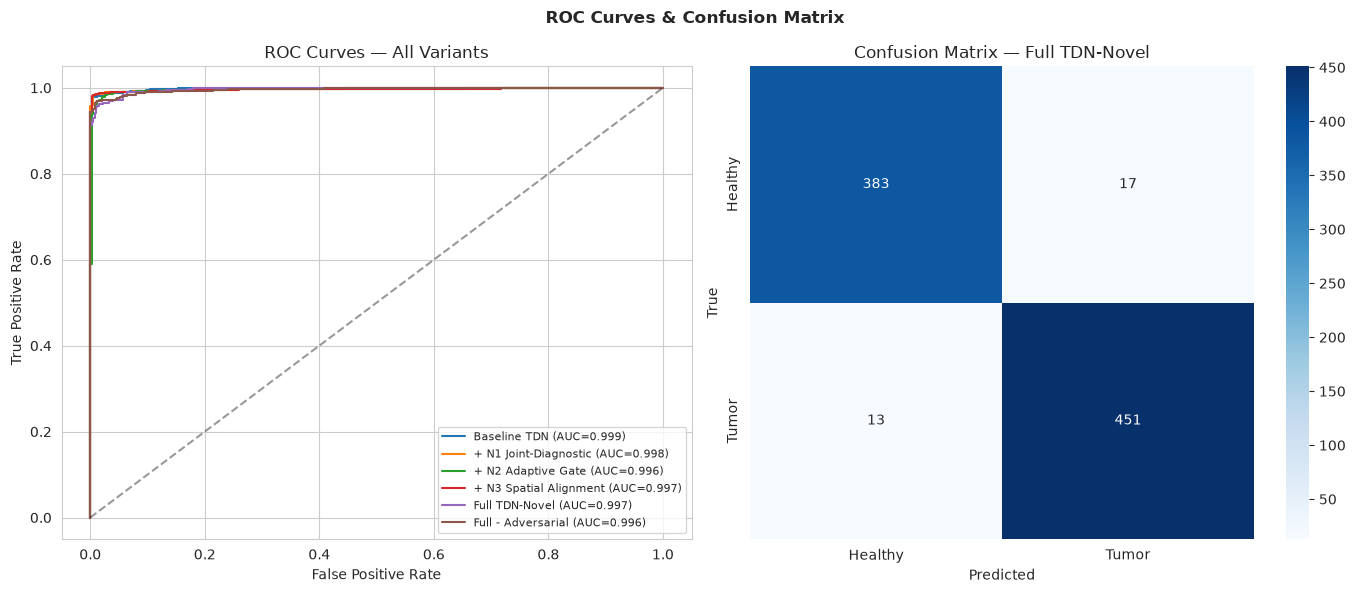

In [ ]:
# ============================================================================
# CELL 29 — ROC CURVES & CONFUSION MATRIX
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name in VARIANT_NAMES:
    entry = loaded_models[name]
    fused, _, _, _ = predict_fused(entry, A_te, B_te)
    y_prob = predict_proba(entry["classifier"], fused, batch_size=16).ravel()
    fpr, tpr, _ = roc_curve(Y_te.ravel(), y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves — All Variants"); axes[0].legend(fontsize=8, loc="lower right")

entry = loaded_models[FULL_KEY]
fused, _, _, _ = predict_fused(entry, A_te, B_te)
y_pred = (predict_proba(entry["classifier"], fused, batch_size=16).ravel() >= .5).astype(int)
sns.heatmap(confusion_matrix(Y_te.ravel(), y_pred, labels=[0, 1]), annot=True, fmt="d",
            cmap="Blues", xticklabels=["Healthy", "Tumor"], yticklabels=["Healthy", "Tumor"],
            ax=axes[1])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
axes[1].set_title(f"Confusion Matrix — {FULL_KEY}")
plt.suptitle("ROC Curves & Confusion Matrix", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig9_roc_confusion.png", dpi=300); plt.show()


In [ ]:
# ============================================================================
# CELL 30 — EXPORT TABLES & FIGURE INVENTORY
# ============================================================================
recomputed_df.to_csv(f"{FIGURE_DIR}/table2_ablation_recomputed.csv")
pd.read_csv(f"{CHECKPOINT_DIR}/table3_resolution_results.csv", index_col=0)\
  .to_csv(f"{FIGURE_DIR}/table3_resolution_results.csv")
stat_df.to_csv(f"{FIGURE_DIR}/table4_statistical_significance.csv", index=False)

print("Tables:")
for f in sorted(os.listdir(FIGURE_DIR)):
    if f.endswith(".csv"): print("  -", f)
print("\nFigures (300 dpi):")
for f in sorted(os.listdir(FIGURE_DIR)):
    if f.endswith(".png"): print("  -", f)
print(f"\nPipeline complete. Everything in {FIGURE_DIR}")


Tables:
  - table2_ablation_recomputed.csv
  - table3_resolution_results.csv
  - table4_statistical_significance.csv

Figures (300 dpi):
  - fig1a_class_balance.png
  - fig1b_preprocessing.png
  - fig1c_histograms.png
  - fig1d_sample_pairs.png
  - fig2d_preview_untrained.png
  - fig3_training_curves.png
  - fig3b_ablation_bars.png
  - fig4_qualitative.png
  - fig5_gate_map.png
  - fig6_alignment.png
  - fig7_uncertainty.png
  - fig8_gradcam.png
  - fig9_roc_confusion.png

Pipeline complete. Everything in /home/dhrubo/Videos/plos/TDN_pipeline/paper_figures


In [ ]:
# ============================================================================
# CELL 31 — GPU CLEANUP
# Run between experiments to release cached blocks. Note that PyTorch's caching
# allocator holds freed blocks for reuse, so `nvidia-smi` will keep showing them
# as used until empty_cache() is called -- that is expected, not a leak.
# ============================================================================
for _name in ["gan", "trained_models", "loaded_models", "entry", "fused", "preds"]:
    if _name in globals():
        try:
            del globals()[_name]
        except Exception:
            pass
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    for i in range(torch.cuda.device_count()):
        free, total = torch.cuda.mem_get_info(i)
        alloc = torch.cuda.memory_allocated(i) // 1024**2
        reserv = torch.cuda.memory_reserved(i) // 1024**2
        print(f"cuda:{i} free={free//1024**2}MB/{total//1024**2}MB "
              f"| torch allocated={alloc}MB reserved={reserv}MB")
else:
    print("No CUDA device.")


cuda:0 free=22866MB/24117MB | torch allocated=0MB reserved=0MB
cuda:1 free=23363MB/24126MB | torch allocated=65MB reserved=104MB
